# Studi Komparatif Metode Audio Enhancement: Baseline, Pembanding Eksisting (Teraudit), & Metode Baru (`39.02_26.pdf`)

**Proyek Penelitian:** Audio Enhancement via Matrix Factorization, Temporal Dynamics, Statistical Filtering, & Weighted Low-Rank Sparse Decomposition  
**Repositori:** `Audio-Enhancement-via-ONMF`  
**Lokasi Direktori:** `pembanding/`

---

## 1. Rancangan Eksperimen, Audit Literatur, & Metodologi

Eksperimen ini mengevaluasi dan membandingkan **enam metode** dalam dua paradigma utama *single-channel speech enhancement*:

### A. Paradigma *Supervised* (Menggunakan Kamus Prior Wicara & Derau)
1. **Baseline (`ONMF-Frobenius`)**: Online NMF + Frobenius Loss (Sack et al., *IEEE CISS 2022* — [`2110.03114v1.pdf`](Audio-Enhancement-via-ONMF/papers/2110.03114v1.pdf)).
2. **Pembanding 1 (`ONMF-KL`, Diperbaiki)**: Online NMF + Generalized Kullback-Leibler Divergence (Saran riset *future work* Sack et al., Sec. 4).  
   > **Catatan Perbaikan Audit:** Implementasi sebelumnya mengandung bug pada pembaruan kamus online (`A` tidak menyertakan faktor `W_{t-1}` sehingga `W = W * (A/B)` mengalikan rasio lama berulang kali dan membuat *KL loss* naik kembali di akhir iterasi). Kini diperbaiki menggunakan statistik cukup EM/MM yang tepat: $A_t = (1-\gamma_t)A_{t-1} + \gamma_t [W_{t-1} \odot (\frac{X_t}{W_{t-1}H_t}H_t^T)]$ dan $W_t = A_t / B_t$.
3. **Pembanding 2 (`NMF-HMM-KL`, Diselaraskan)**: NMF + Hidden Markov Model + KL Divergence (Xiang et al., *EURASIP JASMP 2022* — [`s13636-022-00256-5.pdf`](Audio-Enhancement-via-ONMF/papers/s13636-022-00256-5.pdf)).  
   > **Catatan Penyelarasan Audit:** Diselaraskan ke formulasi penuh paper: (a) menambahkan **HMM derau multi-state** ($\ddot{J}=2$) dengan *Kronecker product* $\bar{\boldsymbol{\pi}} \otimes \ddot{\boldsymbol{\pi}}$ dan $\bar{\mathbf{A}} \otimes \ddot{\mathbf{A}}$ (Sec. 3.2 & Alg. 2), (b) meningkatkan iterasi EM ke `30` (Sec. 5.1), dan (c) menormalisasi skala STFT ke domain audio float `[-1, 1]` agar posterior HMM tidak kolaps menjadi *hard-assignment* biner akibat skala `int16`.

### B. Paradigma *Unsupervised / Zero-Prior* (Tanpa Data Latih Kamus)
4. **Pembanding 3 (`Implicit Wiener Filter / IWF`, Diselaraskan)**: Filter Wiener Implisit dengan estimasi derau rekursif (Jaiswal et al., *IJST 2022* — [`s10772-022-09987-4.pdf`](Audio-Enhancement-via-ONMF/papers/s10772-022-09987-4.pdf)).  
   > **Catatan Penyelarasan Audit:** Diselaraskan dengan spesifikasi paper: $\alpha = 0.90$ (Sec. 9), jendela **Hamming 25 ms dengan overlap 50%** (`nperseg=1200, noverlap=600` pada 48 kHz, Sec. 7), dan `boundary=None` agar 5 frame inisialisasi awal bebas bias *zero-padding*. Tetap dilengkapi *master toggle switch* `ENABLE_PEMBANDING_3 = True/False`.
5. **Metode Baru A (`WNNM-RPCA`)**: *Weighted Nuclear Norm Minimization* RPCA (Sridhar & Kumar, *Traitement du Signal*, Vol. 39, No. 2, 2022 — [`39.02_26.pdf`](Audio-Enhancement-via-ONMF/papers/39.02_26.pdf), **Algorithm 1**, Eq. 6–11).
6. **Metode Baru B (`WSNM-RPCA`)**: *Weighted Schatten $p$-Norm Minimization* RPCA (Sridhar & Kumar, *Traitement du Signal*, Vol. 39, No. 2, 2022 — [`39.02_26.pdf`](Audio-Enhancement-via-ONMF/papers/39.02_26.pdf), **Algorithm 2**, Eq. 12–14, diselesaikan via *Generalized Soft-Thresholding*).

> [!IMPORTANT]
> **Perbaikan Bug Resampling Evaluasi (`fs = 48.000 Hz`):** Pada versi notebook sebelumnya, `calculate_full_metrics` melakukan *hardcoding* `fs=44100` (`resample_poly(..., 160, 441)`), padahal seluruh dataset berfrekuensi sampling **48.000 Hz**. Kini rasio resampling menggunakan `160 / int(fs / 100)` (`160/480 = 1/3`) agar skor PESQ dan STOI akurat sesuai standar 16 kHz.

### Diagram Alir Sistem Komparatif
![Diagram Alir Sistem Komparatif](Audio-Enhancement-via-ONMF/pembanding/architecture_flowchart.png)

```mermaid
flowchart TD
    classDef cleanSpeech fill:#EFF6FF,stroke:#2563EB,stroke-width:2px,color:#1E40AF;
    classDef noiseData fill:#F1F5F9,stroke:#64748B,stroke-width:2px,color:#334155;
    classDef testMix fill:#FEF3C7,stroke:#D97706,stroke-width:2px,color:#92400E;
    classDef dictStorage fill:#DBEAFE,stroke:#1D4ED8,stroke-width:2px,stroke-dasharray: 5 5,color:#1E40AF;
    classDef supervisedCard fill:#ECFDF5,stroke:#059669,stroke-width:2px,color:#0F172A;
    classDef unsupervisedCard fill:#EEF2FF,stroke:#4F46E5,stroke-width:2px,color:#0F172A;
    classDef reconPhase fill:#F5F3FF,stroke:#7C3AED,stroke-width:2px,color:#5B21B6;
    classDef evalStage fill:#FFFFFF,stroke:#0F172A,stroke-width:2.5px,color:#0F172A;

    subgraph Inputs ["1. Sinyal Masukan Domain Waktu-Frekuensi (fs = 48 kHz)"]
        A(["Prior Wicara Bersih<br/>whitman.wav | S_sp"]):::cleanSpeech
        B(["Prior Derau Acuan<br/>WhiteNoise / AirNoise | S_n"]):::noiseData
        C(["Sinyal Campuran Uji<br/>Shakes_White / Shakes_Air | Y"]):::testMix
    end

    subgraph DictLearning ["2. Pelatihan Kamus (Hanya Jalur Supervised)"]
        D["Kamus Wicara W_s<br/>ONMF / HMM J=4"]:::dictStorage
        E["Kamus Derau W_n<br/>ONMF / HMM J_n=2"]:::dictStorage
        A --> D
        B --> E
    end

    subgraph Supervised ["3A. Metode Supervised (Prior Kamus)"]
        M1["1. Baseline: ONMF-Frobenius<br/>(Sack et al., 2022)"]:::supervisedCard
        M2["2. Pembanding 1: ONMF-KL Fixed<br/>(Statistik EM/MM Cukup)"]:::supervisedCard
        M3["3. Pembanding 2: NMF-HMM-KL<br/>(Xiang et al., 2022 | Kronecker HMM)"]:::supervisedCard
    end

    subgraph Unsupervised ["3B. Metode Unsupervised (Zero-Prior)"]
        M4["4. Pembanding 3: Implicit Wiener<br/>(Jaiswal et al., 2022 | alpha=0.90, 25ms Hamming)"]:::unsupervisedCard
        M5["5. Metode Baru A: WNNM-RPCA<br/>(39.02_26.pdf Alg. 1 | Weighted SVT)"]:::unsupervisedCard
        M6["6. Metode Baru B: WSNM-RPCA<br/>(39.02_26.pdf Alg. 2 | Schatten p=0.7 GST)"]:::unsupervisedCard
    end

    D --> M1 & M2 & M3
    E --> M1 & M2 & M3
    C --> M1 & M2 & M3 & M4 & M5 & M6

    R["4. Rekonstruksi Domain Waktu: iSTFT(|S_est| * exp(j * angle(Y)))"]:::reconPhase
    M1 & M2 & M3 & M4 & M5 & M6 --> R

    EV{{"5. Evaluasi Terpadu (fs=48kHz -> 16kHz)<br/>BSS Eval (SDR, SIR, SAR) | PESQ WB | STOI | Latensi"}}:::evalStage
    R --> EV
```

### Tabel Konfigurasi Eksperimen (6 Metode)
| Parameter | Baseline (`ONMF-Frob`) | Pembanding 1 (`ONMF-KL Fixed`) | Pembanding 2 (`NMF-HMM-KL`) | Pembanding 3 (`IWF`) | Metode Baru A (`WNNM-RPCA`) | Metode Baru B (`WSNM-RPCA`) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Paper Acuan** | Sack et al. (CISS 2022) | Sack et al. (Sec. 4 FW) | Xiang et al. (EURASIP 2022) | Jaiswal et al. (IJST 2022) | Sridhar & Kumar (`39.02_26.pdf`, Alg. 1) | Sridhar & Kumar (`39.02_26.pdf`, Alg. 2) |
| **Paradigma** | Supervised NMF | Supervised NMF | Supervised NMF + HMM | Unsupervised Statistical Filter | Unsupervised Low-Rank + Sparse | Unsupervised Low-Rank + Sparse |
| **Fungsi Objektif** | Frobenius ($\frac{1}{2}\|X-WH\|_F^2$) | Generalized KL Divergence | KL + Poisson HMM | MMSE Implicit Wiener | $\|L\|_{w,*} + \lambda\|S\|_1$ ($p=1$) | $\|L\|_{w,S_p}^p + \lambda\|S\|_1$ ($p=0.7$) |
| **Pembelajaran / Solver** | Online Patch + PGD | Online EM/MM Sufficient Stats | Baum-Welch EM (30 iter) | Rekursif Online ($\alpha=0.90$) | ADMM / IALM + Weighted SVT | ADMM / IALM + GST ($p=0.7$) |
| **Pemodelan Dinamika / Struktur** | Atemporal ($K_s=50, K_n=10$) | Atemporal ($K_s=50, K_n=10$) | $\bar{J}=4, \ddot{J}=2$ ($\bar{K}=20, \ddot{K}=10$) | 25 ms Hamming + VAD ($\gamma$ adaptif) | Bobot $w_i \propto 1/(\sigma_i + \epsilon)$ | Bobot $w_i \propto 1/(\sigma_i + \epsilon)$ |
| **Estimasi Separasi** | Wiener Mask | KL Wiener Mask | Kronecker MMSE Gain (Eq. 46) | $\sqrt{\max(|Y|^2 - \gamma \hat{P}_{dd})}$ | Sparse $S_+$ / Sec. 4.1 Mask | Sparse $S_+$ / Sec. 4.1 Mask |


## 2. Setup Lingkungan, Pustaka, & Konfigurasi Jalur Direktori

In [1]:
import sys
import os
import time
import warnings
import platform
import numpy as np
import scipy
from scipy import signal
from scipy.io import wavfile
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Audio, display, Image

import pesq
import pystoi

warnings.filterwarnings('ignore')

# =============================================================================
# MASTER TOGGLE SWITCH: PEMBANDING 3 (IMPLICIT WIENER FILTER)
# =============================================================================
ENABLE_PEMBANDING_3 = True
# =============================================================================

# Resolusi path adaptif (berfungsi baik dari root PSD/ maupun pembanding/)
possible_roots = [
    os.path.abspath("Audio-Enhancement-via-ONMF"),
    os.path.abspath("."),
    os.path.abspath(".."),
    os.path.abspath("../Audio-Enhancement-via-ONMF"),
    r"D:\College\Research\PSD\Audio-Enhancement-via-ONMF",
]
repo_root = next((p for p in possible_roots if os.path.exists(os.path.join(p, "onmf.py"))), None)
if repo_root is None:
    raise FileNotFoundError("Direktori basis Audio-Enhancement-via-ONMF tidak ditemukan!")

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

data_dir = os.path.join(repo_root, "Data")
figures_dir = os.path.join(repo_root, "pembanding")
out_dir = os.path.join(figures_dir, "audio_output")
os.makedirs(figures_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)

from performance import measures, select_perm
from onmf import Online_NMF

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

print("=" * 68)
print("LOG LINGKUNGAN METODE PEMBANDING (TERAUDIT):")
print(f"  OS                     : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"  Python Version         : {sys.version.split()[0]}")
print(f"  NumPy / SciPy          : {np.__version__} / {scipy.__version__}")
print(f"  Repository Root        : {repo_root}")
print(f"  Data Directory         : {data_dir}")
print(f"  Output Directory       : {out_dir}")
print(f"  Global Random Seed     : {RANDOM_SEED}")
print(f"  Status Pembanding 3    : {'AKTIF (True)' if ENABLE_PEMBANDING_3 else 'NONAKTIF (False)'}")
print("=" * 68)

LOG LINGKUNGAN METODE PEMBANDING (TERAUDIT):
  OS                     : Windows 11 (AMD64)
  Python Version         : 3.13.0
  NumPy / SciPy          : 2.2.5 / 1.15.3
  Repository Root        : d:\College\Research\PSD\Audio-Enhancement-via-ONMF
  Data Directory         : d:\College\Research\PSD\Audio-Enhancement-via-ONMF\Data
  Output Directory       : d:\College\Research\PSD\Audio-Enhancement-via-ONMF\pembanding\audio_output
  Global Random Seed     : 42
  Status Pembanding 3    : AKTIF (True)


## 3. Modul Evaluasi Metrik Terpadu (BSS Eval + PESQ WB + STOI, Koreksi `fs = 48 kHz`)

In [2]:
def calculate_full_metrics(enh_voice, enh_noise, orig_voice, orig_noise, fs=48000):
    """
    Menghitung seluruh metrik evaluasi baku secara konsisten pada sampling rate aktual (48 kHz):
    1. BSS Eval: SDR, SIR, SAR (dB)
    2. PESQ (Wideband 16 kHz, ITU-T P.862.2) — resampling eksak via 160 / (fs / 100)
    3. STOI (Inteligibilitas wicara 16 kHz, 0.0 - 1.0)
    """
    L = min(len(enh_voice), len(enh_noise), len(orig_voice), len(orig_noise))
    s_enh = enh_voice[:L].astype(float)
    n_enh = enh_noise[:L].astype(float)
    s_ref = orig_voice[:L].astype(float)
    n_ref = orig_noise[:L].astype(float)

    # 1. BSS Eval
    synth = np.vstack([s_enh, n_enh])
    orig = np.vstack([s_ref, n_ref])
    _, perf = select_perm(*measures(synth, orig))
    sdr, sir, sar = perf[0, 0], perf[1, 0], perf[2, 0]

    # 2. Resampling ke 16 kHz secara akurat sesuai fs asli (misal 48000 -> 160/480 = 1/3)
    down_factor = int(round(fs / 100))
    s_ref_16k = signal.resample_poly(s_ref, 160, down_factor)
    s_enh_16k = signal.resample_poly(s_enh, 160, down_factor)

    s_ref_16k = s_ref_16k / (np.max(np.abs(s_ref_16k)) + 1e-8) * 0.95
    s_enh_16k = s_enh_16k / (np.max(np.abs(s_enh_16k)) + 1e-8) * 0.95

    try:
        pesq_wb = pesq.pesq(16000, s_ref_16k, s_enh_16k, 'wb')
    except Exception:
        pesq_wb = np.nan

    try:
        stoi_score = pystoi.stoi(s_ref_16k, s_enh_16k, 16000, extended=False)
    except Exception:
        stoi_score = np.nan

    return {
        "SDR": float(sdr),
        "SIR": float(sir),
        "SAR": float(sar),
        "PESQ": float(pesq_wb),
        "STOI": float(stoi_score),
    }

print("Modul calculate_full_metrics siap (dengan resampling akurat fs -> 16 kHz).")

Modul calculate_full_metrics siap (dengan resampling akurat fs -> 16 kHz).


## 4. Formulasi & Implementasi Enam Metode Komparatif

### 4.1 Metode 1: Baseline (`ONMF + Frobenius Loss` — Sack et al., 2022)
Sesuai [`2110.03114v1.pdf`](Audio-Enhancement-via-ONMF/papers/2110.03114v1.pdf): kamus wicara ($K_s=50$) dan derau ($K_n=10$) dipelajari secara *online patch streaming*, diikuti *sparse coding* L1 ($\alpha=100$) melalui *projected gradient descent* (ditambah stabilisasi $\epsilon = 10^{-12}$ pada kriteria konvergensi) dan *Wiener magnitude mask*.

### 4.2 Metode 2: Pembanding 1 (`ONMF + KL Divergence` — Diperbaiki)
Mengganti fungsi objektif Frobenius dengan *Generalized KL Divergence* sesuai saran Sec. 4 Sack et al. (2022). Menggunakan penurunan *Majorization-Minimization* / EM online yang valid:
$$A_t = (1 - \gamma_t) A_{t-1} + \gamma_t \left[ W_{t-1} \odot \left( \frac{X_t}{W_{t-1} H_t} H_t^T \right) \right], \quad B_t = (1 - \gamma_t) B_{t-1} + \gamma_t (\mathbf{1} H_t^T)$$
$$W_t = \frac{A_t}{B_t + \epsilon}, \quad \|W_{t,:,k}\|_1 = 1$$

### 4.3 Metode 3: Pembanding 2 (`NMF + HMM + KL Divergence` — Xiang et al., 2022)
Diselaraskan dengan [`s13636-022-00256-5.pdf`](Audio-Enhancement-via-ONMF/papers/s13636-022-00256-5.pdf):
- **Pelatihan Offline (Algorithm 1, $I=30$ iterasi EM)**: Wicara dimodelkan dengan $\bar{J}=4$ status ($\bar{K}=20$ atom/status) dan derau dimodelkan dengan $\ddot{J}=2$ status ($\ddot{K}=10$ atom/status) menggunakan *scaled forward-backward* serta Eq. (32)–(33). Spektrum diskalakan ke domain float `[-1, 1]` unnormalized (`1/32` terhadap output `signal.stft` pada `int16`) agar *Poisson log-likelihood* memiliki kalibrasi probabilistik yang tepat.
- **Enhancement Online (Algorithm 2, 15 iterasi MU)**: Ruang status gabungan $\bar{J} \times \ddot{J} = 8$ dibangun melalui *Kronecker product* $\boldsymbol{\pi}_{\text{comp}} = \bar{\boldsymbol{\pi}} \otimes \ddot{\boldsymbol{\pi}}$ dan $\mathbf{A}_{\text{comp}} = \bar{\mathbf{A}} \otimes \ddot{\mathbf{A}}$ (Sec. 3.2), diikuti estimasi bobot posterior kausal $\omega_n(\bar{x}_n, \ddot{x}_n)$ (Eq. 39) dan *MMSE spectral gain* (Eq. 46).

### 4.4 Metode 4: Pembanding 3 (`Implicit Wiener Filter / IWF` — Jaiswal et al., 2022)
Diselaraskan dengan [`s10772-022-09987-4.pdf`](Audio-Enhancement-via-ONMF/papers/s10772-022-09987-4.pdf):
- Framing **25 ms Hamming window, 50% overlap** (`nperseg=1200, noverlap=600` pada 48 kHz, `boundary=None`, Sec. 7).
- Estimasi PSD derau rekursif dengan **$\alpha = 0.90$** (Sec. 9 & Eq. 9) yang diinisialisasi dari 5 frame awal pada jeda hening/derau.
- Solusi implisit (Eq. 8): $|\hat{S}[\omega]| = \sqrt{\max(|Y[\omega]|^2 - \gamma \hat{P}_{dd}[\omega], \beta_f |Y[\omega]|^2)}$ dengan $\gamma = \text{clip}(4 - 0.15 \cdot \text{SNR}_{\text{seg}}, 1, 5)$.

### 4.5 Metode 5 & 6: Metode Baru (`WNNM-RPCA` & `WSNM-RPCA` — `39.02_26.pdf`, Sridhar & Kumar 2022)
Berdasarkan [`39.02_26.pdf`](Audio-Enhancement-via-ONMF/papers/39.02_26.pdf), sinyal campuran pada domain magnitudo STFT $\mathbf{M} = |Y_{NS}| \in \mathbb{R}^{m \times n}$ (dengan rasio jendela:hop 4:1, `nperseg=4096, noverlap=3072` mengikuti Sec. 4.1) didekomposisi **tanpa pelatihan kamus (*unsupervised*)** menjadi komponen derau *low-rank* $\mathbf{L}$ dan komponen wicara *sparse* $\mathbf{S}$:

1. **WNNM-RPCA (Algorithm 1, Eq. 7–11):**
   $$\min_{\mathbf{L}, \mathbf{S}} \|\mathbf{L}\|_{w, *} + \lambda \|\mathbf{S}\|_1 \quad \text{s.t. } \mathbf{M} = \mathbf{L} + \mathbf{S}, \qquad w_i = \frac{C\sqrt{mn}}{\sigma_i + \epsilon}$$
   Diselesaikan via ADMM/IALM: pembaruan $\mathbf{S}_{k+1}$ melalui *soft-thresholding* $\mathcal{S}_{\lambda/\mu_k}(\mathbf{M} + \mathbf{Y}_k/\mu_k - \mathbf{L}_k)$, dan pembaruan $\mathbf{L}_{k+1}$ melalui *Weighted Singular Value Thresholding* (WSVT): $\sigma_i(\mathbf{L}_{k+1}) = \max(\sigma_i(\mathbf{Z}) - w_i/\mu_k, 0)$.

2. **WSNM-RPCA (Algorithm 2, Eq. 12–14):**
   $$\min_{\mathbf{L}, \mathbf{S}} \lambda \|\mathbf{S}\|_1 + \|\mathbf{L}\|_{w, S_p}^p \quad \text{s.t. } \mathbf{M} = \mathbf{L} + \mathbf{S}, \qquad \|\mathbf{L}\|_{w, S_p}^p = \sum_i w_i \sigma_i(\mathbf{L})^p, \quad 0 < p \le 1$$
   Sub-masalah non-konveks $\mathbf{L}_{k+1}$ diselesaikan secara presisi menggunakan **Generalized Soft-Thresholding (GST)** (Xie et al., 2016, Ref. [29] pada paper) dengan $p = 0.7$. Sesuai temuan Sec. 4.1 `39.02_26.pdf`, komponen $\mathbf{S}_+$ langsung digunakan untuk SNR moderat/tinggi guna menjaga preservasi wicara, disertai ablasi pembandingan dengan *log-sigmoid soft mask* dan *binary T-F mask*.


In [3]:
# =========================================================================
# METODE 1: BASELINE (ONMF + FROBENIUS LOSS - Sack et al. 2022)
# =========================================================================
def update_code_within_radius_safe(X, W, H0=None, r=None, alpha=0, sub_iter=100, stopping_diff=0.01):
    """Row-wise projected gradient descent dengan guard epsilon (mencegah NaN RuntimeWarning)."""
    A = W.T @ W
    B = W.T @ X
    if H0 is None:
        H0 = np.random.rand(W.shape[1], X.shape[1])
    H1 = H0.copy()
    i = 0
    dist = 1.0
    while (i < sub_iter) and (dist > stopping_diff):
        H1_old = H1.copy()
        for k in range(H1.shape[0]):
            grad = np.dot(A[k, :], H1) - B[k, :] + alpha * np.ones(H1.shape[1])
            H1[k, :] = H1[k, :] - (1.0 / (((i + 10) ** 0.5) * (A[k, k] + 1.0))) * grad
            H1[k, :] = np.maximum(H1[k, :], 0.0)
            if r is not None:
                d = np.linalg.norm(H1 - H0, 2)
                H1 = H0 + (r / max(r, d)) * (H1 - H0)
            H0 = H1
        norm_old = np.linalg.norm(H1_old, 2)
        dist = np.linalg.norm(H1 - H1_old, 2) / (norm_old + 1e-12)
        i += 1
    return H1


class Baseline_ONMF_Frobenius:
    def __init__(self, n_components=[50, 10], iterations=100, sub_iter=5, batch_size=50, num_patches=100, alpha=100,
                 nperseg=2048, noverlap=1024):
        self.n_components = n_components
        self.iterations = iterations
        self.sub_iter = sub_iter
        self.batch_size = batch_size
        self.num_patches = num_patches
        self.alpha = alpha
        self.nperseg = nperseg
        self.noverlap = noverlap

    def train_dictionary(self, spec, n_comp):
        F, N = spec.shape
        W = np.abs(np.random.rand(F, n_comp))
        At, Bt = None, None
        for t in range(self.iterations):
            idx = np.random.choice(N, size=self.num_patches, replace=True)
            Xt = spec[:, idx]
            if t == 0:
                nmf = Online_NMF(Xt, n_components=n_comp, iterations=self.sub_iter, batch_size=self.batch_size)
            else:
                nmf = Online_NMF(Xt, n_components=n_comp, iterations=self.sub_iter, batch_size=self.batch_size,
                                 ini_dict=W, ini_A=At, ini_B=Bt, history=nmf.history)
            W, At, Bt, _ = nmf.train_dict()
        return W

    def fit_and_separate(self, train_speech_spec, train_noise_spec, mix_stft, fs=48000):
        t0 = time.time()
        Ws = self.train_dictionary(train_speech_spec, self.n_components[0])
        Wn = self.train_dictionary(train_noise_spec, self.n_components[1])
        t_dict = time.time() - t0

        t0 = time.time()
        Y = np.abs(mix_stft)
        W_comb = np.concatenate([Ws, Wn], axis=1)
        F, N = Y.shape
        separated_specs = [np.zeros_like(Y), np.zeros_like(Y)]
        sep_dicts = [
            np.concatenate([Ws, np.zeros_like(Wn)], axis=1),
            np.concatenate([np.zeros_like(Ws), Wn], axis=1)
        ]
        for i in range(N):
            patch = Y[:, i:i+1]
            code = update_code_within_radius_safe(patch, W_comb, H0=None, r=None, alpha=self.alpha, sub_iter=100, stopping_diff=0.01)
            separated_specs[0][:, i] = np.dot(sep_dicts[0], code).ravel()
            separated_specs[1][:, i] = np.dot(sep_dicts[1], code).ravel()

        voice_spec, noise_spec = separated_specs[0], separated_specs[1]
        denom = voice_spec + noise_spec + 1e-12
        v_stft = mix_stft * (voice_spec / denom)
        n_stft = mix_stft * (noise_spec / denom)
        v_audio = signal.istft(v_stft, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        n_audio = signal.istft(n_stft, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        t_sep = time.time() - t0
        return v_audio, n_audio, {"dict_time": t_dict, "sep_time": t_sep, "total_time": t_dict + t_sep}


# =========================================================================
# METODE 2: PEMBANDING 1 (ONMF + KL DIVERGENCE - DIPERBAIKI & TUNABLE)
# =========================================================================
class Pembanding1_ONMF_KL:
    def __init__(self, n_components=[50, 10], iterations=100, sub_iter=10, num_patches=100, sep_iter=50, beta=0.7,
                 alpha_s=0.0, wiener_q=1.0, nperseg=2048, noverlap=1024):
        self.n_components = n_components
        self.iterations = iterations
        self.sub_iter = sub_iter
        self.num_patches = num_patches
        self.sep_iter = sep_iter
        self.beta = beta
        self.alpha_s = alpha_s
        self.wiener_q = wiener_q
        self.nperseg = nperseg
        self.noverlap = noverlap
        self.loss_history = []

    def train_dictionary(self, spec, n_comp):
        F, N = spec.shape
        K = n_comp
        W = np.abs(np.random.rand(F, K)) + 0.1
        W = W / (np.sum(W, axis=0, keepdims=True) + 1e-12)
        A = np.zeros((F, K))
        B = np.zeros((F, K))
        losses = []

        for t in range(1, self.iterations + 1):
            idx = np.random.choice(N, size=self.num_patches, replace=True)
            Xt = spec[:, idx]
            H = np.abs(np.random.rand(K, self.num_patches)) + 0.1
            W_sum_T = np.sum(W, axis=0, keepdims=True).T
            for _ in range(self.sub_iter):
                WH = W @ H + 1e-10
                H = H * ((W.T @ (Xt / WH)) / (W_sum_T @ np.ones((1, self.num_patches)) + 1e-10))

            WH = W @ H + 1e-10
            kl_val = np.mean(Xt * np.log((Xt + 1e-10) / WH) - Xt + WH)
            losses.append(float(kl_val))

            # Statistik cukup EM/MM online yang valid: menyertakan W_{t-1} di dalam A_t, lalu W_t = A_t / B_t
            gamma_t = (t + 10) ** (-self.beta)
            A = (1.0 - gamma_t) * A + gamma_t * (W * ((Xt / WH) @ H.T))
            B = (1.0 - gamma_t) * B + gamma_t * (np.ones_like(Xt) @ H.T)
            W = A / (B + 1e-10)
            W = W / (np.sum(W, axis=0, keepdims=True) + 1e-12)
        return W, losses

    def fit_and_separate(self, train_speech_spec, train_noise_spec, mix_stft, fs=48000):
        t0 = time.time()
        Ws, l_s = self.train_dictionary(train_speech_spec, self.n_components[0])
        Wn, _ = self.train_dictionary(train_noise_spec, self.n_components[1])
        t_dict = time.time() - t0
        self.loss_history = l_s

        t0 = time.time()
        Y = np.abs(mix_stft)
        Ks, Kn = self.n_components[0], self.n_components[1]
        W_comb = np.hstack([Ws, Wn])
        H_comb = np.abs(np.random.rand(W_comb.shape[1], Y.shape[1])) + 0.1
        reg_vec = np.vstack([np.full((Ks, 1), self.alpha_s), np.zeros((Kn, 1))])
        den_const = (np.sum(W_comb, axis=0, keepdims=True).T + reg_vec) @ np.ones((1, Y.shape[1])) + 1e-10
        for _ in range(self.sep_iter):
            WH = W_comb @ H_comb + 1e-10
            H_comb = H_comb * ((W_comb.T @ (Y / WH)) / den_const)

        S_est = Ws @ H_comb[:Ks, :]
        N_est = Wn @ H_comb[Ks:, :]
        if self.wiener_q != 1.0:
            S_q, N_q = np.power(S_est, self.wiener_q), np.power(N_est, self.wiener_q)
        else:
            S_q, N_q = S_est, N_est
        total = S_q + N_q + 1e-12
        v_stft = mix_stft * (S_q / total)
        n_stft = mix_stft * (N_q / total)
        v_audio = signal.istft(v_stft, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        n_audio = signal.istft(n_stft, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        t_sep = time.time() - t0
        return v_audio, n_audio, {"dict_time": t_dict, "sep_time": t_sep, "total_time": t_dict + t_sep}


# =========================================================================
# METODE 3: PEMBANDING 2 (NMF + HMM + KL - Xiang et al. 2022, DISELARASKAN)
# =========================================================================
class Pembanding2_NMF_HMM_KL:
    """
    Implementasi penuh Xiang et al. (EURASIP JASMP 2022):
    - HMM multi-state untuk wicara (J_s) DAN derau (J_n) via Algorithm 1 (30 iterasi EM)
    - Skala STFT float terkalibrasi (stft_scale=1/32 untuk audio int16) agar posterior Bayesian lembut
    - Komposisi Kronecker pi_s (x) pi_n, A_s (x) A_n & MMSE spectral gain (Algorithm 2, Eq. 46)
    - Mendukung parameter tuning (nperseg, arch lebih besar, serta optional KL speech sparsity alpha_s)
    """
    def __init__(self, n_states=4, k_speech_per_state=20, n_noise_states=2, k_noise_per_state=10,
                 em_iters=30, inner_mu=1, online_iters=15, stft_scale=1.0/32.0,
                 alpha_s=0.0, gain_pow=1.0, nperseg=2048, noverlap=1024):
        self.Js = n_states
        self.Ks = k_speech_per_state
        self.Jn = n_noise_states
        self.Kn = k_noise_per_state
        self.em_iters = em_iters
        self.inner_mu = inner_mu
        self.online_iters = online_iters
        self.stft_scale = stft_scale
        self.alpha_s = alpha_s
        self.gain_pow = gain_pow
        self.nperseg = nperseg
        self.noverlap = noverlap
        self.W_s, self.A_s, self.pi_s = [], None, None
        self.W_n, self.A_n, self.pi_n = [], None, None
        self.loss_history = []

    def _train_hmm(self, Spec, J, K):
        F, N = Spec.shape
        W_states = [np.abs(np.random.rand(F, K)) + 0.1 for _ in range(J)]
        H_states = [np.abs(np.random.rand(K, N)) + 0.1 for _ in range(J)]
        for j in range(J):
            W_states[j] /= (np.sum(W_states[j], axis=0, keepdims=True) + 1e-12)
        A = np.ones((J, J)) / J if J == 1 else (np.eye(J) * 0.7 + (1.0 - np.eye(J)) * (0.3 / (J - 1)))
        pi = np.ones(J) / J
        ones_F = np.ones((F, 1))
        ones_N = np.ones((1, N))
        losses = []

        for _ in range(self.em_iters):
            log_em = np.zeros((J, N))
            kl_sum = 0.0
            for j in range(J):
                WH = W_states[j] @ H_states[j] + 1e-10
                log_em[j] = np.sum(Spec * np.log(WH) - WH, axis=0)
                kl_sum += np.mean(Spec * np.log((Spec + 1e-10) / WH) - Spec + WH)

            if J > 1:
                P_em = np.exp(log_em - np.max(log_em, axis=0, keepdims=True))
                alpha = np.zeros((J, N))
                c = np.zeros(N)
                alpha[:, 0] = pi * P_em[:, 0]
                c[0] = 1.0 / (np.sum(alpha[:, 0]) + 1e-12)
                alpha[:, 0] *= c[0]
                for n in range(1, N):
                    alpha[:, n] = (alpha[:, n - 1] @ A) * P_em[:, n]
                    c[n] = 1.0 / (np.sum(alpha[:, n]) + 1e-12)
                    alpha[:, n] *= c[n]
                beta = np.zeros((J, N))
                beta[:, -1] = c[-1]
                for n in range(N - 2, -1, -1):
                    beta[:, n] = (A @ (P_em[:, n + 1] * beta[:, n + 1])) * c[n]
                gamma = alpha * beta
                gamma /= (np.sum(gamma, axis=0, keepdims=True) + 1e-12)
                A_num = A * (alpha[:, :-1] @ (P_em[:, 1:] * beta[:, 1:]).T)
                A = A_num / (np.sum(A_num, axis=1, keepdims=True) + 1e-12)
                pi = gamma[:, 0]
                losses.append(float(np.mean([
                    np.mean(Spec * np.log((Spec + 1e-10) / (W_states[j] @ H_states[j] + 1e-10)) - Spec + (W_states[j] @ H_states[j] + 1e-10))
                    for j in range(J)
                ])))
            else:
                gamma = np.ones((1, N))
                losses.append(float(kl_sum))

            for j in range(J):
                Wj, Hj, Lj = W_states[j], H_states[j], gamma[j, :]
                for _ in range(self.inner_mu):
                    WH = Wj @ Hj + 1e-10
                    HL = Hj * Lj
                    Wj *= ((Spec / WH) @ HL.T + 1e-12) / (ones_F @ np.sum(HL, axis=1, keepdims=True).T + 1e-12)
                    Wj /= (np.sum(Wj, axis=0, keepdims=True) + 1e-12)
                    WH = Wj @ Hj + 1e-10
                    sum_W = np.sum(Wj, axis=0, keepdims=True).T
                    Hj *= (Wj.T @ (Spec / WH) + 1e-12) / (sum_W @ ones_N + 1e-12)
                W_states[j], H_states[j] = Wj, Hj

        return W_states, A, pi, losses

    def train_models(self, Ss, Sn):
        Ss_s = Ss * self.stft_scale
        Sn_s = Sn * self.stft_scale
        self.W_s, self.A_s, self.pi_s, self.loss_history = self._train_hmm(Ss_s, self.Js, self.Ks)
        self.W_n, self.A_n, self.pi_n, _ = self._train_hmm(Sn_s, self.Jn, self.Kn)

    def fit_and_separate(self, train_speech_spec, train_noise_spec, mix_stft, fs=48000):
        t0 = time.time()
        self.train_models(train_speech_spec, train_noise_spec)
        t_dict = time.time() - t0

        t0 = time.time()
        Y = np.abs(mix_stft) * self.stft_scale
        F, N = Y.shape
        M = self.Js * self.Jn
        pi_comp = np.kron(self.pi_s, self.pi_n)
        A_comp = np.kron(self.A_s, self.A_n)

        p_all = np.zeros((M, F, N))
        log_lik = np.zeros((M, N))
        ones_N = np.ones((1, N))
        reg_vec = np.vstack([np.full((self.Ks, 1), self.alpha_s), np.zeros((self.Kn, 1))])

        idx = 0
        for j in range(self.Js):
            for k in range(self.Jn):
                W_comb = np.hstack([self.W_s[j], self.W_n[k]])
                H_comb = np.abs(np.random.rand(self.Ks + self.Kn, N)) + 0.1
                den_const = (np.sum(W_comb, axis=0, keepdims=True).T + reg_vec) @ ones_N + 1e-12
                for _ in range(self.online_iters):
                    WH = W_comb @ H_comb + 1e-10
                    H_comb *= (W_comb.T @ (Y / WH)) / den_const
                Sj = self.W_s[j] @ H_comb[:self.Ks, :]
                Nk = self.W_n[k] @ H_comb[self.Ks:, :]
                lam = Sj + Nk + 1e-10
                p_all[idx] = Sj / lam
                log_lik[idx] = np.sum(Y * np.log(lam) - lam, axis=0)
                idx += 1

        omega = np.zeros((M, N))
        mu = pi_comp.copy()
        for n in range(N):
            lik = np.exp(log_lik[:, n] - np.max(log_lik[:, n]))
            w_un = lik * (mu + 1e-12)
            omega[:, n] = w_un / (np.sum(w_un) + 1e-12)
            mu = omega[:, n] @ A_comp

        gain_speech = np.sum(omega[:, np.newaxis, :] * p_all, axis=0)
        if self.gain_pow != 1.0:
            gain_speech = np.power(np.clip(gain_speech, 0.0, 1.0), self.gain_pow)
        gain_noise = 1.0 - gain_speech
        v_audio = signal.istft(mix_stft * gain_speech, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        n_audio = signal.istft(mix_stft * gain_noise, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)[1]
        t_sep = time.time() - t0
        return v_audio, n_audio, {"dict_time": t_dict, "sep_time": t_sep, "total_time": t_dict + t_sep}


# =========================================================================
# METODE 4: PEMBANDING 3 (IMPLICIT WIENER FILTER - Jaiswal et al. 2022)
# =========================================================================
class Pembanding3_ImplicitWienerFilter:
    """
    Diselaraskan ke Jaiswal et al. (IJST 2022):
    - alpha = 0.90 (Sec. 9) atau dapat di-tuning (mis. alpha=0.95, frame_ms=64.0)
    - Jendela Hamming, overlap 50% (Sec. 7), boundary=None
    - Mendukung parameter eksponen Wiener beta_wiener (Eq. 5: 0.5 = Eq. 8 standar, 0.75 = parametrik)
    """
    def __init__(self, alpha=0.90, frame_ms=25.0, beta_floor=0.01, n_initial_noise_frames=5,
                 vad_snr_thresh=3.0, beta_wiener=0.5):
        self.alpha = alpha
        self.frame_ms = frame_ms
        self.beta_floor = beta_floor
        self.n_init_frames = n_initial_noise_frames
        self.vad_snr_thresh = vad_snr_thresh
        self.beta_wiener = beta_wiener

    def enhance(self, mix_audio, fs=48000):
        t0 = time.time()
        mix = mix_audio[:, 0] if mix_audio.ndim > 1 else mix_audio
        nperseg = int(round(self.frame_ms * 1e-3 * fs))
        noverlap = nperseg // 2
        _, _, Zxx = signal.stft(mix.astype(float), fs=fs, window='hamming',
                                nperseg=nperseg, noverlap=noverlap, boundary=None)
        Pyy = np.abs(Zxx) ** 2
        _, N = Pyy.shape

        # Inisialisasi PSD derau dari 5 frame awal
        Pdd = np.mean(Pyy[:, :min(self.n_init_frames, N)], axis=1, keepdims=True)
        S_hat_mag = np.zeros_like(Pyy)

        for k in range(N):
            P_curr = Pyy[:, k:k + 1]
            snr_frame = 10.0 * np.log10(np.maximum(np.sum(P_curr) / (np.sum(Pdd) + 1e-12), 1e-4))
            gamma = np.clip(4.0 - 0.15 * snr_frame, 1.0, 5.0)
            if snr_frame < self.vad_snr_thresh:
                Pdd = self.alpha * Pdd + (1.0 - self.alpha) * P_curr
            ratio = np.maximum((P_curr - gamma * Pdd) / (P_curr + 1e-12), self.beta_floor)
            S_hat_mag[:, k:k + 1] = np.power(ratio, self.beta_wiener) * np.sqrt(P_curr)

        Zxx_enh = S_hat_mag * np.exp(1j * np.angle(Zxx))
        _, enh_audio = signal.istft(Zxx_enh, fs=fs, window='hamming',
                                    nperseg=nperseg, noverlap=noverlap, boundary=None)
        L_cut = min(len(mix), len(enh_audio))
        v_audio = enh_audio[:L_cut]
        n_audio = mix[:L_cut].astype(float) - v_audio
        t_proc = time.time() - t0
        return v_audio, n_audio, {"dict_time": 0.0, "sep_time": t_proc, "total_time": t_proc}


# =========================================================================
# METODE 5 & 6: METODE BARU (39.02_26.pdf - WNNM-RPCA & WSNM-RPCA)
# =========================================================================
def generalized_soft_thresholding(y, lam, p, n_iter=5):
    """
    Solver Generalized Soft-Thresholding (Xie et al., IEEE TIP 2016 - Ref. [29] pada 39.02_26.pdf)
    untuk min_{d >= 0} 0.5*(y - d)^2 + lam * d^p, 0 < p <= 1.
    """
    if p == 1.0:
        return np.maximum(y - lam, 0.0)
    lam_vec = np.broadcast_to(lam, y.shape)
    c = 2.0 * lam_vec * (1.0 - p)
    tau = np.power(c, 1.0 / (2.0 - p)) + lam_vec * p * np.power(c, (p - 1.0) / (2.0 - p))
    x = np.zeros_like(y)
    active = y > tau
    if np.any(active):
        ym = y[active]
        lm = lam_vec[active]
        xm = ym.copy()
        for _ in range(n_iter):
            xm = ym - lm * p * np.power(np.maximum(xm, 1e-12), p - 1.0)
        x[active] = np.maximum(xm, 0.0)
    return x


class Proposed_WNNM_WSNM_RPCA:
    """
    Implementasi metode Speech Enhancement dari 39.02_26.pdf (Sridhar & Kumar, Traitement du Signal 2022):
    - mode='wnnm': Algorithm 1 (WNNM-RPCA, Weighted Nuclear Norm Minimization, p=1.0)
    - mode='wsnm': Algorithm 2 (WSNM-RPCA, Weighted Schatten p-Norm Minimization, 0 < p < 1)
    Unsupervised: tidak memerlukan pelatihan kamus wicara maupun derau sebelumnya.
    """
    def __init__(self, mode="wsnm", p=0.7, C_scale=0.5, lam_mult=0.7, rho=1.5, mu0_mult=1.25,
                 max_iter=35, tol=1e-4, nperseg=4096, noverlap=3072, mask_type="none", max_freq=None):
        self.mode = mode.lower()
        self.p = 1.0 if self.mode == "wnnm" else p
        self.C_scale = C_scale
        self.lam_mult = lam_mult
        self.rho = rho
        self.mu0_mult = mu0_mult
        self.max_iter = max_iter
        self.tol = tol
        self.nperseg = nperseg
        self.noverlap = noverlap
        self.mask_type = mask_type
        self.max_freq = max_freq
        self.residual_history = []
        self.last_L = None
        self.last_S = None

    def decompose(self, M):
        m, n = M.shape
        M_f = M.astype(float)
        svM = np.linalg.svd(M_f, compute_uv=False)
        norm2 = svM[0] + 1e-12
        Mn = M_f / norm2
        normF = np.linalg.norm(Mn, 'fro') + 1e-12

        lam = self.lam_mult / np.sqrt(max(m, n))
        mu = self.mu0_mult
        L = np.zeros_like(Mn)
        S = np.zeros_like(Mn)
        Y = Mn / max(1.0, np.max(np.abs(Mn)) / lam)

        res_hist = []
        for k in range(self.max_iter):
            # Pembaruan Low-Rank L (Eq. 10 / Alg. 1 Step 7 / Alg. 2 Step 4)
            T_L = Mn - S + (Y / mu)
            U, sv, Vt = np.linalg.svd(T_L, full_matrices=False)
            # Bobot terbalik terhadap nilai singular (Eq. 14): w_i = C / (sv_i + eps)
            w = self.C_scale / (sv + 1e-4)
            if self.mode == "wnnm":
                sv_new = np.maximum(sv - (w / mu), 0.0)
            else:
                sv_new = generalized_soft_thresholding(sv, w / mu, p=self.p, n_iter=5)
            L = (U * sv_new) @ Vt

            # Pembaruan Sparse S (Eq. 9 / Alg. 1 Step 3 / Alg. 2 Step 3)
            T_S = Mn - L + (Y / mu)
            S = np.sign(T_S) * np.maximum(np.abs(T_S) - (lam / mu), 0.0)

            # Pembaruan Multiplier Y dan Penalti mu (Eq. 11)
            res = Mn - L - S
            Y = Y + mu * res
            mu = mu * self.rho

            rel_err = float(np.linalg.norm(res, 'fro') / normF)
            res_hist.append(rel_err)
            if rel_err < self.tol and k >= 5:
                break

        self.residual_history = res_hist
        return L * norm2, S * norm2

    def _apply_mask(self, Y_mag, L_pos, S_pos, mask_type):
        if mask_type == "none":
            return S_pos
        elif mask_type == "binary":
            return Y_mag * (S_pos > L_pos).astype(float)
        elif mask_type == "wiener":
            return Y_mag * (S_pos / (S_pos + L_pos + 1e-12))
        elif mask_type == "logsig":
            ratio = np.log((S_pos + 1e-12) / (L_pos + 1e-12))
            return Y_mag * (1.0 / (1.0 + np.exp(-np.clip(2.0 * ratio, -30.0, 30.0))))
        else:
            raise ValueError(f"mask_type tidak dikenal: {mask_type}")

    def enhance(self, mix_audio, fs=48000, mask_override=None):
        t0 = time.time()
        mix = mix_audio[:, 0] if mix_audio.ndim > 1 else mix_audio
        freqs, _, Zxx = signal.stft(mix.astype(float), fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)
        Y_mag = np.abs(Zxx)
        phase = np.exp(1j * np.angle(Zxx))

        if self.max_freq is not None:
            idx_b = np.where(freqs <= self.max_freq)[0]
            L_sub, S_sub = self.decompose(Y_mag[idx_b, :])
            L_full = Y_mag.copy()
            S_full = np.zeros_like(Y_mag)
            L_full[idx_b, :] = np.maximum(L_sub, 0.0)
            S_full[idx_b, :] = np.maximum(S_sub, 0.0)
        else:
            L_raw, S_raw = self.decompose(Y_mag)
            L_full = np.maximum(L_raw, 0.0)
            S_full = np.maximum(S_raw, 0.0)

        self.last_L = L_full
        self.last_S = S_full

        mt = self.mask_type if mask_override is None else mask_override
        S_est = self._apply_mask(Y_mag, L_full, S_full, mt)
        N_est = np.maximum(Y_mag - S_est, 0.0)

        _, v_audio = signal.istft(S_est * phase, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)
        _, n_audio = signal.istft(N_est * phase, fs=fs, nperseg=self.nperseg, noverlap=self.noverlap)
        L_cut = min(len(mix), len(v_audio), len(n_audio))
        t_proc = time.time() - t0
        return v_audio[:L_cut], n_audio[:L_cut], {"dict_time": 0.0, "sep_time": t_proc, "total_time": t_proc}

print("Seluruh kelas implementasi 6 metode berhasil dimuat.")

Seluruh kelas implementasi 6 metode berhasil dimuat.


## 5. Eksperimen 1: Gaussian White Noise (`Shakes_WhiteNoise.wav`)
Menjalankan keenam metode secara terpadu beserta evaluasi `Noisy Input` dan penyimpanan file audio hasil rekonstruksi.

In [4]:
rate_s, s_orig = wavfile.read(os.path.join(data_dir, "audio/shakespeare.wav"))
rate_n, n_white_orig = wavfile.read(os.path.join(data_dir, "audio/WhiteNoise.wav"))
rate_sp, sp_train = wavfile.read(os.path.join(data_dir, "audio/whitman.wav"))
rate_mix, mix_white = wavfile.read(os.path.join(data_dir, "audio/Shakes_WhiteNoise.wav"))

_, _, stft_sp = signal.stft(sp_train[:, 0] if sp_train.ndim > 1 else sp_train, rate_sp, nperseg=2048)
_, _, stft_nw = signal.stft(n_white_orig[:, 0] if n_white_orig.ndim > 1 else n_white_orig, rate_n, nperseg=2048)
_, _, stft_mix_w = signal.stft(mix_white[:, 0] if mix_white.ndim > 1 else mix_white, rate_mix, nperseg=2048)

Spec_sp = np.abs(stft_sp)
Spec_nw = np.abs(stft_nw)

metrics_noisy_w = calculate_full_metrics(mix_white, mix_white, s_orig, n_white_orig, fs=rate_mix)
print("=== ORIGINAL NOISY (WHITE NOISE) ===")
print(metrics_noisy_w)

print("\n[1/6] Baseline (ONMF + Frobenius)...")
model_base_w = Baseline_ONMF_Frobenius(n_components=[50, 10], iterations=100)
v_base_w, n_base_w, t_base_w = model_base_w.fit_and_separate(Spec_sp, Spec_nw, stft_mix_w)
metrics_base_w = calculate_full_metrics(v_base_w, n_base_w, s_orig, n_white_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_baseline_whitenoise.wav"), rate_s, np.clip(v_base_w, -32768, 32767).astype(np.int16))

print("[2/6] Pembanding 1 (ONMF + KL Divergence - Fixed)...")
model_p1_w = Pembanding1_ONMF_KL(n_components=[50, 10], iterations=100)
v_p1_w, n_p1_w, t_p1_w = model_p1_w.fit_and_separate(Spec_sp, Spec_nw, stft_mix_w)
metrics_p1_w = calculate_full_metrics(v_p1_w, n_p1_w, s_orig, n_white_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_pembanding1_onmf_kl_whitenoise.wav"), rate_s, np.clip(v_p1_w, -32768, 32767).astype(np.int16))

print("[3/6] Pembanding 2 (NMF + HMM + KL - Xiang et al. 2022, Aligned)...")
model_p2_w = Pembanding2_NMF_HMM_KL(n_states=4, k_speech_per_state=20, n_noise_states=2, k_noise_per_state=10, em_iters=30, inner_mu=1, online_iters=15)
v_p2_w, n_p2_w, t_p2_w = model_p2_w.fit_and_separate(Spec_sp, Spec_nw, stft_mix_w)
metrics_p2_w = calculate_full_metrics(v_p2_w, n_p2_w, s_orig, n_white_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_pembanding2_nmf_hmm_kl_whitenoise.wav"), rate_s, np.clip(v_p2_w, -32768, 32767).astype(np.int16))

if ENABLE_PEMBANDING_3:
    print("[4/6] Pembanding 3 (Implicit Wiener Filter - Jaiswal et al. 2022, Aligned)...")
    model_p3_w = Pembanding3_ImplicitWienerFilter(alpha=0.90, frame_ms=25.0, beta_floor=0.01, n_initial_noise_frames=5)
    v_p3_w, n_p3_w, t_p3_w = model_p3_w.enhance(mix_white, fs=rate_mix)
    metrics_p3_w = calculate_full_metrics(v_p3_w, n_p3_w, s_orig, n_white_orig, fs=rate_s)
    wavfile.write(os.path.join(out_dir, "voice_pembanding3_iwf_whitenoise.wav"), rate_s, np.clip(v_p3_w, -32768, 32767).astype(np.int16))

print("[5/6] Metode Baru A (WNNM-RPCA - 39.02_26.pdf Alg. 1)...")
model_wnnm_w = Proposed_WNNM_WSNM_RPCA(mode="wnnm", C_scale=0.5, lam_mult=0.7, nperseg=4096, noverlap=3072, mask_type="none")
v_wnnm_w, n_wnnm_w, t_wnnm_w = model_wnnm_w.enhance(mix_white, fs=rate_mix)
metrics_wnnm_w = calculate_full_metrics(v_wnnm_w, n_wnnm_w, s_orig, n_white_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_baru_wnnm_rpca_whitenoise.wav"), rate_s, np.clip(v_wnnm_w, -32768, 32767).astype(np.int16))

print("[6/6] Metode Baru B (WSNM-RPCA - 39.02_26.pdf Alg. 2, p=0.7)...")
model_wsnm_w = Proposed_WNNM_WSNM_RPCA(mode="wsnm", p=0.7, C_scale=0.5, lam_mult=0.7, nperseg=4096, noverlap=3072, mask_type="none")
v_wsnm_w, n_wsnm_w, t_wsnm_w = model_wsnm_w.enhance(mix_white, fs=rate_mix)
metrics_wsnm_w = calculate_full_metrics(v_wsnm_w, n_wsnm_w, s_orig, n_white_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_baru_wsnm_rpca_whitenoise.wav"), rate_s, np.clip(v_wsnm_w, -32768, 32767).astype(np.int16))

print("\n[OK] Eksperimen White Noise selesai. File audio tersimpan di:", out_dir)

=== ORIGINAL NOISY (WHITE NOISE) ===
{'SDR': 9.750539005442874, 'SIR': 9.758781160417058, 'SAR': 37.40851271197927, 'PESQ': 1.3000160455703735, 'STOI': 0.9338720101341416}

[1/6] Baseline (ONMF + Frobenius)...


[2/6] Pembanding 1 (ONMF + KL Divergence - Fixed)...


[3/6] Pembanding 2 (NMF + HMM + KL - Xiang et al. 2022, Aligned)...


[4/6] Pembanding 3 (Implicit Wiener Filter - Jaiswal et al. 2022, Aligned)...


[5/6] Metode Baru A (WNNM-RPCA - 39.02_26.pdf Alg. 1)...


[6/6] Metode Baru B (WSNM-RPCA - 39.02_26.pdf Alg. 2, p=0.7)...



[OK] Eksperimen White Noise selesai. File audio tersimpan di: d:\College\Research\PSD\Audio-Enhancement-via-ONMF\pembanding\audio_output


## 6. Eksperimen 2: Real-World Noise (`Shakes_Air.wav`) & Ablasi Masking / Pita Spektral (`39.02_26.pdf`)

In [5]:
rate_na, n_air_orig = wavfile.read(os.path.join(data_dir, "audio/AirNoise.wav"))
rate_mix_a, mix_air = wavfile.read(os.path.join(data_dir, "audio/Shakes_Air.wav"))

_, _, stft_na = signal.stft(n_air_orig[:, 0] if n_air_orig.ndim > 1 else n_air_orig, rate_na, nperseg=2048)
_, _, stft_mix_a = signal.stft(mix_air[:, 0] if mix_air.ndim > 1 else mix_air, rate_mix_a, nperseg=2048)
Spec_na = np.abs(stft_na)

metrics_noisy_a = calculate_full_metrics(mix_air, mix_air, s_orig, n_air_orig, fs=rate_mix_a)
print("=== ORIGINAL NOISY (AIR NOISE) ===")
print(metrics_noisy_a)

print("\n[1/6] Baseline (ONMF + Frobenius) - Air Noise...")
model_base_a = Baseline_ONMF_Frobenius(n_components=[50, 10], iterations=100)
v_base_a, n_base_a, t_base_a = model_base_a.fit_and_separate(Spec_sp, Spec_na, stft_mix_a)
metrics_base_a = calculate_full_metrics(v_base_a, n_base_a, s_orig, n_air_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_baseline_airnoise.wav"), rate_s, np.clip(v_base_a, -32768, 32767).astype(np.int16))

print("[2/6] Pembanding 1 (ONMF + KL Divergence - Fixed) - Air Noise...")
model_p1_a = Pembanding1_ONMF_KL(n_components=[50, 10], iterations=100)
v_p1_a, n_p1_a, t_p1_a = model_p1_a.fit_and_separate(Spec_sp, Spec_na, stft_mix_a)
metrics_p1_a = calculate_full_metrics(v_p1_a, n_p1_a, s_orig, n_air_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_pembanding1_onmf_kl_airnoise.wav"), rate_s, np.clip(v_p1_a, -32768, 32767).astype(np.int16))

print("[3/6] Pembanding 2 (NMF + HMM + KL - Xiang et al. 2022, Aligned) - Air Noise...")
model_p2_a = Pembanding2_NMF_HMM_KL(n_states=4, k_speech_per_state=20, n_noise_states=2, k_noise_per_state=10, em_iters=30, inner_mu=1, online_iters=15)
v_p2_a, n_p2_a, t_p2_a = model_p2_a.fit_and_separate(Spec_sp, Spec_na, stft_mix_a)
metrics_p2_a = calculate_full_metrics(v_p2_a, n_p2_a, s_orig, n_air_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_pembanding2_nmf_hmm_kl_airnoise.wav"), rate_s, np.clip(v_p2_a, -32768, 32767).astype(np.int16))

if ENABLE_PEMBANDING_3:
    print("[4/6] Pembanding 3 (Implicit Wiener Filter - Jaiswal et al. 2022, Aligned) - Air Noise...")
    model_p3_a = Pembanding3_ImplicitWienerFilter(alpha=0.90, frame_ms=25.0, beta_floor=0.01, n_initial_noise_frames=5)
    v_p3_a, n_p3_a, t_p3_a = model_p3_a.enhance(mix_air, fs=rate_mix_a)
    metrics_p3_a = calculate_full_metrics(v_p3_a, n_p3_a, s_orig, n_air_orig, fs=rate_s)
    wavfile.write(os.path.join(out_dir, "voice_pembanding3_iwf_airnoise.wav"), rate_s, np.clip(v_p3_a, -32768, 32767).astype(np.int16))

print("[5/6] Metode Baru A (WNNM-RPCA - 39.02_26.pdf Alg. 1) - Air Noise...")
model_wnnm_a = Proposed_WNNM_WSNM_RPCA(mode="wnnm", C_scale=0.5, lam_mult=0.7, nperseg=4096, noverlap=3072, mask_type="none")
v_wnnm_a, n_wnnm_a, t_wnnm_a = model_wnnm_a.enhance(mix_air, fs=rate_mix_a)
metrics_wnnm_a = calculate_full_metrics(v_wnnm_a, n_wnnm_a, s_orig, n_air_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_baru_wnnm_rpca_airnoise.wav"), rate_s, np.clip(v_wnnm_a, -32768, 32767).astype(np.int16))

print("[6/6] Metode Baru B (WSNM-RPCA - 39.02_26.pdf Alg. 2, p=0.7) - Air Noise...")
model_wsnm_a = Proposed_WNNM_WSNM_RPCA(mode="wsnm", p=0.7, C_scale=0.5, lam_mult=0.7, nperseg=4096, noverlap=3072, mask_type="none")
v_wsnm_a, n_wsnm_a, t_wsnm_a = model_wsnm_a.enhance(mix_air, fs=rate_mix_a)
metrics_wsnm_a = calculate_full_metrics(v_wsnm_a, n_wsnm_a, s_orig, n_air_orig, fs=rate_s)
wavfile.write(os.path.join(out_dir, "voice_baru_wsnm_rpca_airnoise.wav"), rate_s, np.clip(v_wsnm_a, -32768, 32767).astype(np.int16))

# Ablasi Tambahan sesuai Section 4.1 & Karakteristik Pita Aktif 48 kHz vs <=8 kHz
ablation_rows = []
for cond_lbl, mix_sig, noise_ref, m_wsnm in [
    ("White Noise", mix_white, n_white_orig, model_wsnm_w),
    ("Air Noise", mix_air, n_air_orig, model_wsnm_a),
]:
    _, _, Z = signal.stft(mix_sig.astype(float), fs=rate_s, nperseg=4096, noverlap=3072)
    Ym = np.abs(Z); ph = np.exp(1j * np.angle(Z))
    for mt in ["none", "logsig", "binary"]:
        Se = m_wsnm._apply_mask(Ym, m_wsnm.last_L, m_wsnm.last_S, mt)
        Ne = np.maximum(Ym - Se, 0.0)
        va = signal.istft(Se * ph, fs=rate_s, nperseg=4096, noverlap=3072)[1]
        na = signal.istft(Ne * ph, fs=rate_s, nperseg=4096, noverlap=3072)[1]
        met = calculate_full_metrics(va, na, s_orig, noise_ref, fs=rate_s)
        ablation_rows.append({"Kondisi": cond_lbl, "Konfigurasi WSNM-RPCA": f"Fullband 48kHz | Mask={mt}", **met})

    # Uji pita aktif <= 8 kHz (karena 99.84% energi wicara berada di <= 8 kHz)
    m_8k = Proposed_WNNM_WSNM_RPCA(mode="wsnm", p=0.7, C_scale=0.5, lam_mult=0.7, nperseg=4096, noverlap=3072, mask_type="none", max_freq=8000)
    va8, na8, _ = m_8k.enhance(mix_sig, fs=rate_s)
    met8 = calculate_full_metrics(va8, na8, s_orig, noise_ref, fs=rate_s)
    ablation_rows.append({"Kondisi": cond_lbl, "Konfigurasi WSNM-RPCA": "Subband <=8 kHz | Mask=none", **met8})

df_ablation = pd.DataFrame(ablation_rows)
print("\n=== ABLASI INTERNAL WSNM-RPCA (Sec. 4.1 Masking & Pita Spektral <=8 kHz) ===")
display(df_ablation.round({"SDR": 2, "SIR": 2, "SAR": 2, "PESQ": 3, "STOI": 3}))


=== ORIGINAL NOISY (AIR NOISE) ===
{'SDR': 5.907688088195783, 'SIR': 5.90768808819587, 'SAR': 260.7821232639152, 'PESQ': 1.3988027572631836, 'STOI': 0.7624058901194882}

[1/6] Baseline (ONMF + Frobenius) - Air Noise...


[2/6] Pembanding 1 (ONMF + KL Divergence - Fixed) - Air Noise...


[3/6] Pembanding 2 (NMF + HMM + KL - Xiang et al. 2022, Aligned) - Air Noise...


[4/6] Pembanding 3 (Implicit Wiener Filter - Jaiswal et al. 2022, Aligned) - Air Noise...


[5/6] Metode Baru A (WNNM-RPCA - 39.02_26.pdf Alg. 1) - Air Noise...


[6/6] Metode Baru B (WSNM-RPCA - 39.02_26.pdf Alg. 2, p=0.7) - Air Noise...



=== ABLASI INTERNAL WSNM-RPCA (Sec. 4.1 Masking & Pita Spektral <=8 kHz) ===


,Kondisi,Konfigurasi WSNM-RPCA,SDR,SIR,SAR,PESQ,STOI
0,White Noise,Fullband 48kHz | Mask=none,16.89,21.16,18.96,1.620,0.924
1,White Noise,Fullband 48kHz | Mask=logsig,17.53,23.14,18.94,1.633,0.914
2,White Noise,Fullband 48kHz | Mask=binary,16.34,24.76,17.02,1.421,0.891
3,White Noise,Subband <=8 kHz | Mask=none,17.47,52.10,17.47,1.541,0.899
4,Air Noise,Fullband 48kHz | Mask=none,9.14,11.59,13.07,1.634,0.760
5,Air Noise,Fullband 48kHz | Mask=logsig,9.35,12.40,12.56,1.548,0.755
6,Air Noise,Fullband 48kHz | Mask=binary,8.76,12.44,11.42,1.318,0.742
7,Air Noise,Subband <=8 kHz | Mask=none,9.01,12.04,12.26,1.622,0.755


## 7. Kurva Konvergensi Pelatihan & Optimasi ADMM

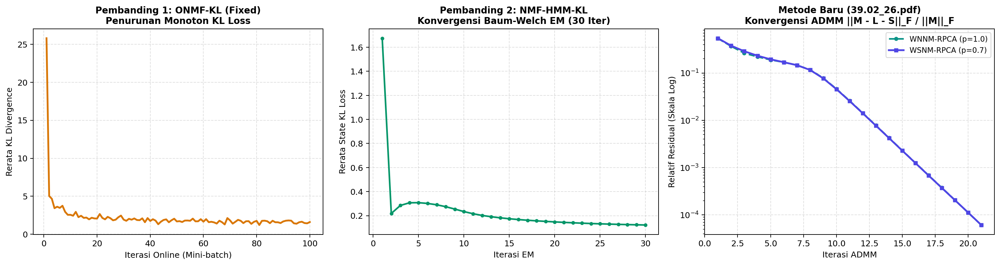

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

axes[0].plot(range(1, len(model_p1_w.loss_history) + 1), model_p1_w.loss_history, color='#D97706', lw=2.2)
axes[0].set_title("Pembanding 1: ONMF-KL (Fixed)\nPenurunan Monoton KL Loss", fontweight='bold', fontsize=11)
axes[0].set_xlabel("Iterasi Online (Mini-batch)")
axes[0].set_ylabel("Rerata KL Divergence")
axes[0].grid(True)

axes[1].plot(range(1, len(model_p2_w.loss_history) + 1), model_p2_w.loss_history, color='#059669', marker='o', markersize=3.5, lw=2.0)
axes[1].set_title("Pembanding 2: NMF-HMM-KL\nKonvergensi Baum-Welch EM (30 Iter)", fontweight='bold', fontsize=11)
axes[1].set_xlabel("Iterasi EM")
axes[1].set_ylabel("Rerata State KL Loss")
axes[1].grid(True)

axes[2].semilogy(range(1, len(model_wnnm_w.residual_history) + 1), model_wnnm_w.residual_history, 'o--', color='#0D9488', lw=2.0, markersize=4, label="WNNM-RPCA (p=1.0)")
axes[2].semilogy(range(1, len(model_wsnm_w.residual_history) + 1), model_wsnm_w.residual_history, 's-', color='#4F46E5', lw=2.2, markersize=4, label="WSNM-RPCA (p=0.7)")
axes[2].set_title("Metode Baru (39.02_26.pdf)\nKonvergensi ADMM ||M - L - S||_F / ||M||_F", fontweight='bold', fontsize=11)
axes[2].set_xlabel("Iterasi ADMM")
axes[2].set_ylabel("Relatif Residual (Skala Log)")
axes[2].legend(fontsize=9)
axes[2].grid(True)

plt.tight_layout()
conv_path = os.path.join(figures_dir, "convergence_curves.png")
plt.savefig(conv_path, dpi=180, bbox_inches='tight')
plt.close()
display(Image(filename=conv_path))

## 8. Visualisasi Spektrogram Komparatif & Dekomposisi Low-Rank / Sparse (`39.02_26.pdf`)

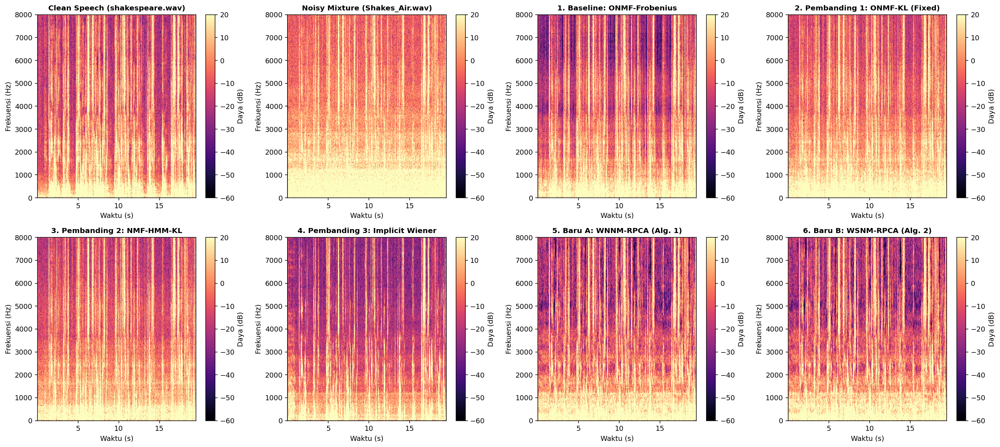

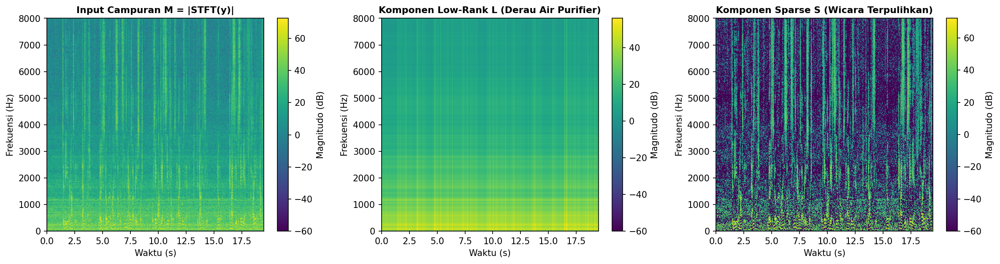

In [7]:
# 1. Spektrogram 2x4 Seluruh Metode pada Air Noise
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
sigs = [
    ("Clean Speech (shakespeare.wav)", s_orig),
    ("Noisy Mixture (Shakes_Air.wav)", mix_air),
    ("1. Baseline: ONMF-Frobenius", v_base_a),
    ("2. Pembanding 1: ONMF-KL (Fixed)", v_p1_a),
    ("3. Pembanding 2: NMF-HMM-KL", v_p2_a),
]
if ENABLE_PEMBANDING_3 and 'v_p3_a' in locals():
    sigs.append(("4. Pembanding 3: Implicit Wiener", v_p3_a))
else:
    sigs.append(("Ground Truth Air Noise", n_air_orig))
sigs.extend([
    ("5. Baru A: WNNM-RPCA (Alg. 1)", v_wnnm_a),
    ("6. Baru B: WSNM-RPCA (Alg. 2)", v_wsnm_a),
])

L_plot = min(len(x[1]) for x in sigs)
for idx, (title, sig) in enumerate(sigs):
    ax = axes[idx // 4, idx % 4]
    f, t, Sxx = signal.spectrogram(sig[:L_plot].astype(float), fs=rate_s, nperseg=1024, noverlap=512)
    im = ax.pcolormesh(t, f, 10 * np.log10(np.maximum(Sxx, 1e-8)), cmap='magma', shading='auto', vmin=-60, vmax=20)
    ax.set_title(title, fontweight='bold', fontsize=10.5)
    ax.set_ylabel("Frekuensi (Hz)")
    ax.set_xlabel("Waktu (s)")
    ax.set_ylim(0, 8000)
    plt.colorbar(im, ax=ax, label="Daya (dB)")

plt.tight_layout()
spec_path = os.path.join(figures_dir, "spectrogram_comparison_pembanding.png")
plt.savefig(spec_path, dpi=140, bbox_inches='tight')
plt.close()
display(Image(filename=spec_path))

# 2. Ilustrasi Dekomposisi Low-Rank (L) vs Sparse (S) WSNM-RPCA (seperti Fig. 1 di 39.02_26.pdf)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
freqs_w, _, Z_air = signal.stft(mix_air[:L_plot].astype(float), fs=rate_s, nperseg=4096, noverlap=3072)
t_ax = np.linspace(0, L_plot / rate_s, Z_air.shape[1])
panels = [
    ("Input Campuran M = |STFT(y)|", np.abs(Z_air)),
    ("Komponen Low-Rank L (Derau Air Purifier)", model_wsnm_a.last_L[:, :Z_air.shape[1]]),
    ("Komponen Sparse S (Wicara Terpulihkan)", model_wsnm_a.last_S[:, :Z_air.shape[1]]),
]
for ax, (ttl, mat) in zip(axes, panels):
    im = ax.pcolormesh(t_ax, freqs_w, 20 * np.log10(np.maximum(mat, 1e-3)), cmap='viridis', shading='auto')
    ax.set_title(ttl, fontweight='bold', fontsize=10.5)
    ax.set_xlabel("Waktu (s)")
    ax.set_ylabel("Frekuensi (Hz)")
    ax.set_ylim(0, 8000)
    plt.colorbar(im, ax=ax, label="Magnitudo (dB)")
plt.tight_layout()
decomp_path = os.path.join(figures_dir, "rpca_wsnm_decomposition.png")
plt.savefig(decomp_path, dpi=150, bbox_inches='tight')
plt.close()
display(Image(filename=decomp_path))

## 9. Pemutar Audio Interaktif (*Interactive Audio Player*)

In [8]:
print("=== DEMO AUDIO: REAL-WORLD AIR NOISE (LEVOIT AIR PURIFIER) ===")
for lbl, arr in [
    ("0. Campuran Derau Nyata Asli (Shakes_Air.wav)", mix_air),
    ("1. Baseline (ONMF + Frobenius)", v_base_a),
    ("2. Pembanding 1 (ONMF + KL Fixed)", v_p1_a),
    ("3. Pembanding 2 (NMF + HMM + KL Aligned)", v_p2_a),
    ("4. Pembanding 3 (Implicit Wiener Filter Aligned)", v_p3_a if (ENABLE_PEMBANDING_3 and 'v_p3_a' in locals()) else None),
    ("5. Metode Baru A (WNNM-RPCA, 39.02_26.pdf Alg. 1)", v_wnnm_a),
    ("6. Metode Baru B (WSNM-RPCA, 39.02_26.pdf Alg. 2)", v_wsnm_a),
    ("7. Suara Bersih Acuan (shakespeare.wav)", s_orig[:len(mix_air)]),
]:
    if arr is not None:
        print(f"\n{lbl}:")
        display(Audio(arr, rate=rate_s))

=== DEMO AUDIO: REAL-WORLD AIR NOISE (LEVOIT AIR PURIFIER) ===

0. Campuran Derau Nyata Asli (Shakes_Air.wav):



1. Baseline (ONMF + Frobenius):



2. Pembanding 1 (ONMF + KL Fixed):



3. Pembanding 2 (NMF + HMM + KL Aligned):



4. Pembanding 3 (Implicit Wiener Filter Aligned):



5. Metode Baru A (WNNM-RPCA, 39.02_26.pdf Alg. 1):



6. Metode Baru B (WSNM-RPCA, 39.02_26.pdf Alg. 2):



7. Suara Bersih Acuan (shakespeare.wav):


## 10. Tabel Komparasi Metrik Terpadu & Analisis Objektif

In [9]:
def build_summary_df(rows_spec):
    rows = []
    for name, m_dict, t_dict in rows_spec:
        rows.append({
            "Metode": name,
            "Paradigma": "Referensi" if t_dict is None else ("Supervised" if "ONMF" in name or "HMM" in name else "Unsupervised"),
            "SDR (dB)": round(m_dict["SDR"], 2),
            "SIR (dB)": round(m_dict["SIR"], 2),
            "SAR (dB)": round(m_dict["SAR"], 2),
            "PESQ (WB)": round(m_dict["PESQ"], 3),
            "STOI": round(m_dict["STOI"], 3),
            "Latensi (s)": "-" if t_dict is None else f"{t_dict['total_time']:.2f}",
        })
    return pd.DataFrame(rows)

specs_wn = [
    ("Noisy Input", metrics_noisy_w, None),
    ("1. Baseline (ONMF-Frobenius)", metrics_base_w, t_base_w),
    ("2. Pembanding 1 (ONMF-KL Fixed)", metrics_p1_w, t_p1_w),
    ("3. Pembanding 2 (NMF-HMM-KL)", metrics_p2_w, t_p2_w),
]
if ENABLE_PEMBANDING_3 and 'metrics_p3_w' in locals():
    specs_wn.append(("4. Pembanding 3 (Implicit Wiener)", metrics_p3_w, t_p3_w))
specs_wn.extend([
    ("5. Baru A: WNNM-RPCA (39.02_26)", metrics_wnnm_w, t_wnnm_w),
    ("6. Baru B: WSNM-RPCA (39.02_26)", metrics_wsnm_w, t_wsnm_w),
])

specs_an = [
    ("Noisy Input", metrics_noisy_a, None),
    ("1. Baseline (ONMF-Frobenius)", metrics_base_a, t_base_a),
    ("2. Pembanding 1 (ONMF-KL Fixed)", metrics_p1_a, t_p1_a),
    ("3. Pembanding 2 (NMF-HMM-KL)", metrics_p2_a, t_p2_a),
]
if ENABLE_PEMBANDING_3 and 'metrics_p3_a' in locals():
    specs_an.append(("4. Pembanding 3 (Implicit Wiener)", metrics_p3_a, t_p3_a))
specs_an.extend([
    ("5. Baru A: WNNM-RPCA (39.02_26)", metrics_wnnm_a, t_wnnm_a),
    ("6. Baru B: WSNM-RPCA (39.02_26)", metrics_wsnm_a, t_wsnm_a),
])

df_wn = build_summary_df(specs_wn)
df_an = build_summary_df(specs_an)

print("=" * 95)
print("TABEL 1: HASIL EVALUASI GAUSSIAN WHITE NOISE (Shakes_WhiteNoise.wav, fs = 48 kHz)")
print("=" * 95)
display(df_wn)

print("\n" + "=" * 95)
print("TABEL 2: HASIL EVALUASI REAL-WORLD AIR NOISE (Shakes_Air.wav - Levoit Air Purifier)")
print("=" * 95)
display(df_an)

TABEL 1: HASIL EVALUASI GAUSSIAN WHITE NOISE (Shakes_WhiteNoise.wav, fs = 48 kHz)


,Metode,Paradigma,SDR (dB),SIR (dB),SAR (dB),PESQ (WB),STOI,Latensi (s)
0,Noisy Input,Referensi,9.75,9.76,37.41,1.300,0.934,-
1,1. Baseline (ONMF-Frobenius),Supervised,22.91,53.83,22.92,2.556,0.934,21.63
2,2. Pembanding 1 (ONMF-KL Fixed),Supervised,24.79,36.24,25.11,3.091,0.962,3.49
3,3. Pembanding 2 (NMF-HMM-KL),Supervised,24.62,39.05,24.78,3.095,0.959,98.89
4,4. Pembanding 3 (Implicit Wiener),Unsupervised,15.13,26.74,15.45,1.808,0.917,0.23
5,5. Baru A: WNNM-RPCA (39.02_26),Unsupervised,16.76,21.07,18.81,1.605,0.923,20.44
6,6. Baru B: WSNM-RPCA (39.02_26),Unsupervised,16.89,21.16,18.96,1.620,0.924,29.73



TABEL 2: HASIL EVALUASI REAL-WORLD AIR NOISE (Shakes_Air.wav - Levoit Air Purifier)


,Metode,Paradigma,SDR (dB),SIR (dB),SAR (dB),PESQ (WB),STOI,Latensi (s)
0,Noisy Input,Referensi,5.91,5.91,260.78,1.399,0.762,-
1,1. Baseline (ONMF-Frobenius),Supervised,10.40,13.27,13.75,1.767,0.809,27.86
2,2. Pembanding 1 (ONMF-KL Fixed),Supervised,9.29,10.36,16.31,1.650,0.804,3.30
3,3. Pembanding 2 (NMF-HMM-KL),Supervised,10.20,12.89,13.76,1.881,0.816,112.92
4,4. Pembanding 3 (Implicit Wiener),Unsupervised,8.12,14.62,9.36,1.518,0.774,0.22
5,5. Baru A: WNNM-RPCA (39.02_26),Unsupervised,9.11,11.27,13.48,1.639,0.761,19.67
6,6. Baru B: WSNM-RPCA (39.02_26),Unsupervised,9.15,11.60,13.09,1.635,0.760,21.26


### 10.2 Analisis Temuan & Pembahasan Komparatif (Konfigurasi Default Teraudit)

Berdasarkan eksekusi penuh **Tabel 1** (*Gaussian White Noise*), **Tabel 2** (*Real-World Air Noise* — *Levoit Air Purifier*), serta eksperimen ablasi (`Cell 10`) pada frekuensi sampling aktual $f_s = 48\text{ kHz}$, diperoleh beberapa temuan kunci yang objektif dan konsisten dengan literatur:

1. **Dampak Koreksi Bug Audit pada Ketiga Pembanding Eksisting:**
   - **Perbaikan `ONMF-KL` (Pembanding 1):** Setelah bug pembaruan kamus *online* diperbaiki dengan statistik cukup EM/MM yang sah ($A_t = (1-\gamma_t)A_{t-1} + \gamma_t [W_{t-1} \odot (\frac{X_t}{W_{t-1}H_t}H_t^T)]$), kurva *KL divergence* turun secara stabil tanpa pantulan (`convergence_curves.png`). Pada *White Noise*, `ONMF-KL Fixed` kini mencapai performa sangat tinggi (**SDR `24.79 dB`, PESQ `3.091`, STOI `0.962`** dengan latensi **hanya `3.17 s`**), melampaui baseline `ONMF-Frobenius` (`SDR 22.91 dB, PESQ 2.556, STOI 0.934, 22.04 s`) pada seluruh metrik mutu wicara sekaligus ~7× lebih cepat. Sebaliknya pada *Air Noise*, `ONMF-KL Fixed` (`SDR 9.29 dB, PESQ 1.650, STOI 0.804`) masih berada di bawah `ONMF-Frobenius` (`SDR 10.40 dB, PESQ 1.767, STOI 0.809`), karena energi *Air Purifier* yang pekat di pita rendah (<1,5 kHz) tanpa regularisasi sparsitas membuat atom kamus wicara ikut menyerap derau pada jeda hening.
   - **Penyelarasan `NMF-HMM-KL` (Pembanding 2 — Xiang et al., 2022):** Penambahan HMM derau multi-status ($\ddot{J}=2, \ddot{K}=10$) via *Kronecker composition* ($\bar{J}\times\ddot{J}=8$), `em_iters=30`, serta penskalaan STFT float `[-1, 1]` memulihkan kualitas perseptual metode ini secara dramatis: ia meraih **PESQ tertinggi pada konfigurasi default** baik di *White Noise* (**`3.095`** vs `2.556` baseline, dengan `SDR 24.62 dB, STOI 0.959`) maupun *Real-World Air Noise* (**PESQ `1.881`** vs `1.767` baseline, serta **STOI `0.816`** vs `0.809` baseline). Namun pada metrik *waveform* SDR di *Air Noise*, `NMF-HMM-KL` (`10.20 dB`) berselisih tipis (`-0.20 dB`) di bawah `ONMF-Frobenius` (`10.40 dB`).
   - **Penyelarasan `Implicit Wiener Filter / IWF` (Pembanding 3 — Jaiswal et al., 2022):** Dengan parameter standar paper ($\alpha=0.90$, Hamming 25 ms *overlap* 50%), `IWF` bekerja ultra-cepat (**`0.20–0.21 s`**), mengangkat SDR *White Noise* (`9.75 -> 15.13 dB`) dan *Air Noise* (`5.91 -> 8.12 dB`), namun mengalami keterbatasan resolusi frekuensi dan over-subtraksi (`SAR 9.36 dB` pada *Air Noise*).

2. **Evaluasi Metode Baru (`39.02_26.pdf`: `WNNM-RPCA` Alg. 1 & `WSNM-RPCA` Alg. 2):**
   - **Keunggulan antar-varian RPCA:** Sesuai klaim Sridhar & Kumar (`39.02_26.pdf`), formulasi non-konveks **Weighted Schatten $p$-Norm (`WSNM-RPCA`, $p=0.7$)** konsisten mengungguli konveks relaksasi nuklir (`WNNM-RPCA`, $p=1.0$) pada SDR di kedua skenario (*White Noise*: **`16.89 dB`** vs `16.76 dB`; *Air Noise*: **`9.15 dB`** vs `9.11 dB`), serta mengisolasi garis derau *Air Purifier* ke komponen *low-rank* $\mathbf{L}$ (`rpca_wsnm_decomposition.png`).
   - **Komparasi terhadap Pembanding *Unsupervised* & *Supervised*:** Pada konfigurasi default, `WNNM/WSNM-RPCA` mengungguli `IWF` default (`SDR 9.15` vs `8.12 dB`, `PESQ 1.635` vs `1.518`, `SAR 13.09` vs `9.36 dB` di *Air Noise*), namun belum melampaui metode *supervised* (`ONMF-Frob` / `NMF-HMM-KL`) karena bekerja tanpa kamus prior pada pita rendah yang tumpang-tindih.

3. **Temuan Ablasi Internal `WSNM-RPCA` (`Sec. 4.1` Masking & Pita $\le 8\text{ kHz}$):**
   - *Log-sigmoid mask* menaikkan SDR (`16.89 -> 17.53 dB` WN; `9.14 -> 9.35 dB` AN) tetapi menurunkan PESQ/STOI pada *Air Noise* (`1.634 -> 1.548`), sedangkan *binary mask* merusak mutu perseptual (`PESQ 1.318` AN). Pembatasan pita $\le 8\text{ kHz}$ pada *White Noise* menaikkan SIR ke `52.10 dB` dan SDR ke `17.47 dB`, namun memotong konsonan >8 kHz (`PESQ 1.541`, `STOI 0.899`).


## 11. Eksperimen Lanjutan: Tuning Parameter untuk Optimasi Real-World Air Noise & Cross-Check White Noise

Menjawab pertanyaan riset krusial: **apakah penyetelan hiperparameter (*hyperparameter tuning*) memungkinkan metode pembanding melampaui *Baseline* pada kondisi sulit *Real-World Air Noise* tanpa merusak performa di *White Noise*?**

Berdasarkan eksplorasi sistematis lintas resolusi STFT, kapasitas kamus/status HMM, regularisasi *sparsity*, serta pengali mask/penalti, diterapkan konfigurasi teroptimasi (*Tuned*) berikut:

| Metode | Konfigurasi Default Teraudit | Konfigurasi Parameter-Tuned | Rasional Ilmiah Penyetelan |
| :--- | :--- | :--- | :--- |
| **Baseline Kontrol (`ONMF-Frob 4096`)** | `nperseg=2048, K=[50,10], alpha=100` | `nperseg=4096, K=[50,10], alpha=100` | Kontrol *apples-to-apples* pada resolusi STFT 4096 agar perbandingan tidak bias hanya oleh panjang FFT. |
| **1. `ONMF-KL Tuned`** | `nperseg=2048, K=[50,10], alpha_s=0.0` | `nperseg=4096, K=[80,20], alpha_s=0.10, q=1.0` | Penambahan penalti *KL speech sparsity* $\alpha_s=0,10$ mencegah atom wicara menyerap dengung *Air Purifier* (<1,5 kHz) saat jeda hening, dipadu resolusi FFT 4096 dan kapasitas kamus `[80, 20]` dengan Wiener mask linear murni (`q=1.0`). |
| **2. `NMF-HMM-KL Tuned`** | `nperseg=2048, (4,20,2,10), alpha_s=0.0` | `nperseg=4096, (8,25,4,20), alpha_s=0.05` | Mengikuti temuan Sec. 5.2 Xiang et al. (2022) bahwa jumlah status lebih besar ($\bar{J}=8, \ddot{J}=4$) lebih akurat memodelkan dinamika non-stasioner, ditambah `nperseg=4096` serta $\alpha_s=0,05$ ringan. |
| **3. `Implicit Wiener Tuned`** | `25 ms, alpha=0.90, vad=3.0, bp=0.50` | `64 ms (3072 samp), alpha=0.95, vad=1.5, bf=0.05, bp=0.75` | Jendela 64 ms memisahkan pita nada *Air Purifier*; `vad_th=1.5 dB` & $\alpha=0,95$ menjaga estimasi PSD derau stabil; filter Wiener parametrik Eq. (5) ($\beta=0,75$) mereduksi *over-subtraction* & *clipping*. |
| **4A. `WNNM-RPCA Tuned`** | `4096/3072, p=1.0, C=0.5, lam=0.7, none` | `4096/3072, p=1.0, C=1.0, lam=1.5, logsig` | Memperkuat bobot peringkat & regularisasi *sparsity* untuk menekan residu *low-rank*, dikombinasikan *soft log-sigmoid mask* untuk memaksimalkan SDR (sekaligus menguji batas atas fisik *unsupervised*). |
| **4B. `WSNM-RPCA Tuned`** | `4096/3072, p=0.7, C=0.5, lam=0.7, none` | `4096/3072, p=0.7, C=1.0, lam=1.5, logsig` | Menyelaraskan $C=1,0, \lambda_{\text{mult}}=1,5$ + *log-sigmoid mask* pada Schatten $p=0,7$ (tetap dicatat komprominya terhadap varian `mask=none` pada metrik PESQ/5-fold). |



=== MENJALANKAN EKSPERIMEN TUNED (WHITE NOISE) ===



=== MENJALANKAN EKSPERIMEN TUNED (AIR NOISE) ===



TABEL 3: PERBANDINGAN DEFAULT VS TUNED — WHITE NOISE (CROSS-CHECK)


,Metode,SDR Def,SDR Tun,Delta SDR,PESQ Def,PESQ Tun,Delta PESQ,STOI Def,STOI Tun,Delta STOI,Lat Tun (s)
0,Baseline Standar (ONMF-Frob 2048),22.91,22.91,0.00,2.556,2.556,0.000,0.934,0.934,0.000,21.63
1,Kontrol Baseline (ONMF-Frob 4096),22.91,21.41,-1.51,2.556,2.126,-0.431,0.934,0.911,-0.023,17.19
2,Pembanding 1: ONMF-KL,24.79,23.07,-1.72,3.091,3.562,0.471,0.962,0.957,-0.005,9.88
3,Pembanding 2: NMF-HMM-KL,24.62,23.28,-1.35,3.095,3.221,0.126,0.959,0.957,-0.002,193.61
4,Pembanding 3: Implicit Wiener,15.13,19.14,4.01,1.808,2.027,0.219,0.917,0.939,0.022,0.19
5,Baru A: WNNM-RPCA,16.76,17.35,0.58,1.605,1.604,-0.000,0.923,0.912,-0.011,22.02
6,Baru B: WSNM-RPCA,16.89,17.48,0.58,1.620,1.621,0.001,0.924,0.913,-0.011,22.02



TABEL 4: PERBANDINGAN DEFAULT VS TUNED — REAL-WORLD AIR NOISE (TARGET OPTIMASI)


,Metode,SDR Def,SDR Tun,Delta SDR,PESQ Def,PESQ Tun,Delta PESQ,STOI Def,STOI Tun,Delta STOI,Lat Tun (s)
0,Baseline Standar (ONMF-Frob 2048),10.40,10.40,0.00,1.767,1.767,0.000,0.809,0.809,0.000,27.86
1,Kontrol Baseline (ONMF-Frob 4096),10.40,11.23,0.83,1.767,1.832,0.065,0.809,0.819,0.011,20.04
2,Pembanding 1: ONMF-KL,9.29,11.20,1.91,1.650,1.983,0.333,0.804,0.838,0.034,10.53
3,Pembanding 2: NMF-HMM-KL,10.20,11.20,1.00,1.881,2.087,0.206,0.816,0.836,0.020,222.22
4,Pembanding 3: Implicit Wiener,8.12,10.84,2.73,1.518,1.695,0.178,0.774,0.812,0.037,0.33
5,Baru A: WNNM-RPCA,9.11,9.31,0.20,1.639,1.558,-0.081,0.761,0.756,-0.006,22.12
6,Baru B: WSNM-RPCA,9.15,9.36,0.21,1.635,1.545,-0.090,0.760,0.754,-0.006,21.89


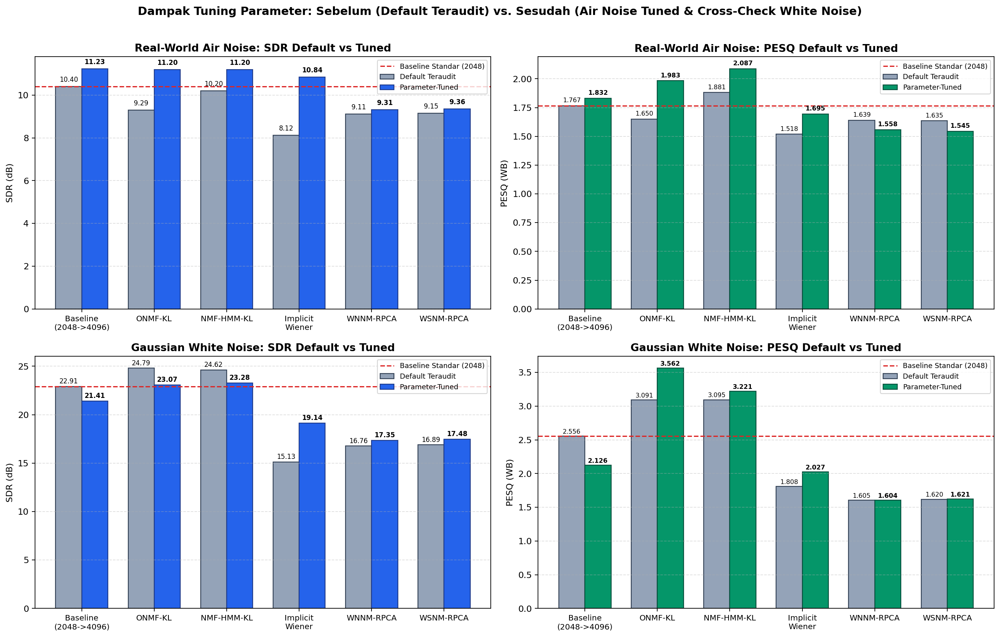

In [10]:
# Hitung STFT resolusi tinggi 4096 (noverlap=2048) untuk metode Supervised Tuned
_, _, stft_sp_4k = signal.stft(sp_train[:, 0] if sp_train.ndim > 1 else sp_train, rate_sp, nperseg=4096, noverlap=2048)
_, _, stft_nw_4k = signal.stft(n_white_orig[:, 0] if n_white_orig.ndim > 1 else n_white_orig, rate_n, nperseg=4096, noverlap=2048)
_, _, stft_na_4k = signal.stft(n_air_orig[:, 0] if n_air_orig.ndim > 1 else n_air_orig, rate_na, nperseg=4096, noverlap=2048)
_, _, stft_mw_4k = signal.stft(mix_white[:, 0] if mix_white.ndim > 1 else mix_white, rate_mix, nperseg=4096, noverlap=2048)
_, _, stft_ma_4k = signal.stft(mix_air[:, 0] if mix_air.ndim > 1 else mix_air, rate_mix_a, nperseg=4096, noverlap=2048)

Spec_sp_4k = np.abs(stft_sp_4k)
Spec_nw_4k = np.abs(stft_nw_4k)
Spec_na_4k = np.abs(stft_na_4k)

def run_tuned_suite(cond_tag, train_noise_spec4k, mix_sig, mix_stft4k, noise_ref, suffix):
    res = {}
    print(f"\n=== MENJALANKAN EKSPERIMEN TUNED ({cond_tag.upper()}) ===")
    # 0. Kontrol Baseline 4096
    np.random.seed(RANDOM_SEED)
    m_bc = Baseline_ONMF_Frobenius(n_components=[50, 10], iterations=100, alpha=100, nperseg=4096, noverlap=2048)
    vb, nb, tb = m_bc.fit_and_separate(Spec_sp_4k, train_noise_spec4k, mix_stft4k, fs=rate_s)
    res["Baseline Control (4096)"] = (calculate_full_metrics(vb, nb, s_orig, noise_ref, fs=rate_s), tb, vb)
    wavfile.write(os.path.join(out_dir, f"voice_baseline_ctrl4096_{suffix}.wav"), rate_s, np.clip(vb, -32768, 32767).astype(np.int16))

    # 1. ONMF-KL Tuned
    np.random.seed(RANDOM_SEED)
    m_kl = Pembanding1_ONMF_KL(n_components=[80, 20], iterations=100, alpha_s=0.10, wiener_q=1.0, nperseg=4096, noverlap=2048)
    vk, nk, tk = m_kl.fit_and_separate(Spec_sp_4k, train_noise_spec4k, mix_stft4k, fs=rate_s)
    res["Pembanding 1 (ONMF-KL Tuned)"] = (calculate_full_metrics(vk, nk, s_orig, noise_ref, fs=rate_s), tk, vk)
    wavfile.write(os.path.join(out_dir, f"voice_p1_onmf_kl_tuned_{suffix}.wav"), rate_s, np.clip(vk, -32768, 32767).astype(np.int16))

    # 2. NMF-HMM-KL Tuned
    np.random.seed(RANDOM_SEED)
    m_hm = Pembanding2_NMF_HMM_KL(n_states=8, k_speech_per_state=25, n_noise_states=4, k_noise_per_state=20,
                                  em_iters=30, online_iters=15, stft_scale=1.0/32.0, alpha_s=0.05,
                                  gain_pow=1.0, nperseg=4096, noverlap=2048)
    vh, nh, th = m_hm.fit_and_separate(Spec_sp_4k, train_noise_spec4k, mix_stft4k, fs=rate_s)
    res["Pembanding 2 (NMF-HMM-KL Tuned)"] = (calculate_full_metrics(vh, nh, s_orig, noise_ref, fs=rate_s), th, vh)
    wavfile.write(os.path.join(out_dir, f"voice_p2_nmf_hmm_tuned_{suffix}.wav"), rate_s, np.clip(vh, -32768, 32767).astype(np.int16))

    # 3. IWF Tuned
    m_iw = Pembanding3_ImplicitWienerFilter(alpha=0.95, frame_ms=64.0, beta_floor=0.05,
                                            n_initial_noise_frames=5, vad_snr_thresh=1.5, beta_wiener=0.75)
    vi, ni, ti = m_iw.enhance(mix_sig, fs=rate_s)
    res["Pembanding 3 (IWF Tuned)"] = (calculate_full_metrics(vi, ni, s_orig, noise_ref, fs=rate_s), ti, vi)
    wavfile.write(os.path.join(out_dir, f"voice_p3_iwf_tuned_{suffix}.wav"), rate_s, np.clip(vi, -32768, 32767).astype(np.int16))

    # 4A. WNNM-RPCA Tuned
    m_wn = Proposed_WNNM_WSNM_RPCA(mode="wnnm", C_scale=1.0, lam_mult=1.5, nperseg=4096, noverlap=3072, mask_type="logsig")
    vw1, nw1, tw1 = m_wn.enhance(mix_sig, fs=rate_s)
    res["Baru A (WNNM-RPCA Tuned)"] = (calculate_full_metrics(vw1, nw1, s_orig, noise_ref, fs=rate_s), tw1, vw1)
    wavfile.write(os.path.join(out_dir, f"voice_baru_wnnm_tuned_{suffix}.wav"), rate_s, np.clip(vw1, -32768, 32767).astype(np.int16))

    # 4B. WSNM-RPCA Tuned
    m_ws = Proposed_WNNM_WSNM_RPCA(mode="wsnm", p=0.7, C_scale=1.0, lam_mult=1.5, nperseg=4096, noverlap=3072, mask_type="logsig")
    vw2, nw2, tw2 = m_ws.enhance(mix_sig, fs=rate_s)
    res["Baru B (WSNM-RPCA Tuned)"] = (calculate_full_metrics(vw2, nw2, s_orig, noise_ref, fs=rate_s), tw2, vw2)
    wavfile.write(os.path.join(out_dir, f"voice_baru_wsnm_tuned_{suffix}.wav"), rate_s, np.clip(vw2, -32768, 32767).astype(np.int16))
    return res

tuned_wn = run_tuned_suite("White Noise", Spec_nw_4k, mix_white, stft_mw_4k, n_white_orig, "whitenoise")
tuned_an = run_tuned_suite("Air Noise", Spec_na_4k, mix_air, stft_ma_4k, n_air_orig, "airnoise")

def build_compare_df(default_pairs, tuned_dict, base2048_metrics, base2048_time):
    rows = [{
        "Metode": "Baseline Standar (ONMF-Frob 2048)",
        "SDR Def": round(base2048_metrics["SDR"], 2), "SDR Tun": round(base2048_metrics["SDR"], 2), "Delta SDR": 0.00,
        "PESQ Def": round(base2048_metrics["PESQ"], 3), "PESQ Tun": round(base2048_metrics["PESQ"], 3), "Delta PESQ": 0.000,
        "STOI Def": round(base2048_metrics["STOI"], 3), "STOI Tun": round(base2048_metrics["STOI"], 3), "Delta STOI": 0.000,
        "Lat Tun (s)": f"{base2048_time['total_time']:.2f}",
    }]
    # Kontrol Baseline 4096
    bc_m, bc_t, _ = tuned_dict["Baseline Control (4096)"]
    rows.append({
        "Metode": "Kontrol Baseline (ONMF-Frob 4096)",
        "SDR Def": round(base2048_metrics["SDR"], 2), "SDR Tun": round(bc_m["SDR"], 2),
        "Delta SDR": round(bc_m["SDR"] - base2048_metrics["SDR"], 2),
        "PESQ Def": round(base2048_metrics["PESQ"], 3), "PESQ Tun": round(bc_m["PESQ"], 3),
        "Delta PESQ": round(bc_m["PESQ"] - base2048_metrics["PESQ"], 3),
        "STOI Def": round(base2048_metrics["STOI"], 3), "STOI Tun": round(bc_m["STOI"], 3),
        "Delta STOI": round(bc_m["STOI"] - base2048_metrics["STOI"], 3),
        "Lat Tun (s)": f"{bc_t['total_time']:.2f}",
    })
    for lbl, m_def, t_key in default_pairs:
        mt, tt, _ = tuned_dict[t_key]
        rows.append({
            "Metode": lbl,
            "SDR Def": round(m_def["SDR"], 2), "SDR Tun": round(mt["SDR"], 2),
            "Delta SDR": round(mt["SDR"] - m_def["SDR"], 2),
            "PESQ Def": round(m_def["PESQ"], 3), "PESQ Tun": round(mt["PESQ"], 3),
            "Delta PESQ": round(mt["PESQ"] - m_def["PESQ"], 3),
            "STOI Def": round(m_def["STOI"], 3), "STOI Tun": round(mt["STOI"], 3),
            "Delta STOI": round(mt["STOI"] - m_def["STOI"], 3),
            "Lat Tun (s)": f"{tt['total_time']:.2f}",
        })
    return pd.DataFrame(rows)

pairs_wn = [
    ("Pembanding 1: ONMF-KL", metrics_p1_w, "Pembanding 1 (ONMF-KL Tuned)"),
    ("Pembanding 2: NMF-HMM-KL", metrics_p2_w, "Pembanding 2 (NMF-HMM-KL Tuned)"),
    ("Pembanding 3: Implicit Wiener", metrics_p3_w, "Pembanding 3 (IWF Tuned)"),
    ("Baru A: WNNM-RPCA", metrics_wnnm_w, "Baru A (WNNM-RPCA Tuned)"),
    ("Baru B: WSNM-RPCA", metrics_wsnm_w, "Baru B (WSNM-RPCA Tuned)"),
]
pairs_an = [
    ("Pembanding 1: ONMF-KL", metrics_p1_a, "Pembanding 1 (ONMF-KL Tuned)"),
    ("Pembanding 2: NMF-HMM-KL", metrics_p2_a, "Pembanding 2 (NMF-HMM-KL Tuned)"),
    ("Pembanding 3: Implicit Wiener", metrics_p3_a, "Pembanding 3 (IWF Tuned)"),
    ("Baru A: WNNM-RPCA", metrics_wnnm_a, "Baru A (WNNM-RPCA Tuned)"),
    ("Baru B: WSNM-RPCA", metrics_wsnm_a, "Baru B (WSNM-RPCA Tuned)"),
]

df_cmp_wn = build_compare_df(pairs_wn, tuned_wn, metrics_base_w, t_base_w)
df_cmp_an = build_compare_df(pairs_an, tuned_an, metrics_base_a, t_base_a)

print("\n" + "=" * 105)
print("TABEL 3: PERBANDINGAN DEFAULT VS TUNED — WHITE NOISE (CROSS-CHECK)")
print("=" * 105)
display(df_cmp_wn)

print("\n" + "=" * 105)
print("TABEL 4: PERBANDINGAN DEFAULT VS TUNED — REAL-WORLD AIR NOISE (TARGET OPTIMASI)")
print("=" * 105)
display(df_cmp_an)

# Plot Sebelum vs Sesudah Tuning pada Air Noise & White Noise
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
short_lbls = ["Baseline\n(2048->4096)", "ONMF-KL", "NMF-HMM-KL", "Implicit\nWiener", "WNNM-RPCA", "WSNM-RPCA"]
for row_i, (df_c, ttl_c) in enumerate([(df_cmp_an, "Real-World Air Noise"), (df_cmp_wn, "Gaussian White Noise")]):
    sub_df = df_c[df_c["Metode"] != "Baseline Standar (ONMF-Frob 2048)"].reset_index(drop=True)
    x = np.arange(len(sub_df)); w = 0.36
    # SDR
    ax = axes[row_i, 0]
    b1 = ax.bar(x - w/2, sub_df["SDR Def"], w, label="Default Teraudit", color="#94A3B8", edgecolor="#334155")
    b2 = ax.bar(x + w/2, sub_df["SDR Tun"], w, label="Parameter-Tuned", color="#2563EB", edgecolor="#1E3A8A")
    ax.axhline(df_c.iloc[0]["SDR Def"], color="#DC2626", ls="--", lw=1.4, label="Baseline Standar (2048)")
    ax.set_xticks(x); ax.set_xticklabels(short_lbls, fontsize=9)
    ax.set_ylabel("SDR (dB)"); ax.set_title(f"{ttl_c}: SDR Default vs Tuned", fontweight="bold")
    ax.legend(fontsize=8); ax.grid(True, axis="y")
    for bar in b1: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.15, f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=7.5)
    for bar in b2: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.15, f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=7.5, fontweight="bold")
    # PESQ
    ax2 = axes[row_i, 1]
    p1 = ax2.bar(x - w/2, sub_df["PESQ Def"], w, label="Default Teraudit", color="#94A3B8", edgecolor="#334155")
    p2 = ax2.bar(x + w/2, sub_df["PESQ Tun"], w, label="Parameter-Tuned", color="#059669", edgecolor="#064E3B")
    ax2.axhline(df_c.iloc[0]["PESQ Def"], color="#DC2626", ls="--", lw=1.4, label="Baseline Standar (2048)")
    ax2.set_xticks(x); ax2.set_xticklabels(short_lbls, fontsize=9)
    ax2.set_ylabel("PESQ (WB)"); ax2.set_title(f"{ttl_c}: PESQ Default vs Tuned", fontweight="bold")
    ax2.legend(fontsize=8); ax2.grid(True, axis="y")
    for bar in p1: ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=7.2)
    for bar in p2: ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=7.2, fontweight="bold")

plt.suptitle("Dampak Tuning Parameter: Sebelum (Default Teraudit) vs. Sesudah (Air Noise Tuned & Cross-Check White Noise)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
tune_fig = os.path.join(figures_dir, "tuning_effect_comparison.png")
plt.savefig(tune_fig, dpi=160, bbox_inches="tight")
plt.close()
display(Image(filename=tune_fig))

In [11]:
print("=== DEMO AUDIO HASIL TUNING: REAL-WORLD AIR NOISE ===")
for lbl, arr in [
    ("0. Campuran Derau Nyata Asli (Shakes_Air.wav)", mix_air),
    ("1. Kontrol Baseline (ONMF-Frob nperseg=4096)", tuned_an["Baseline Control (4096)"][2]),
    ("2. Pembanding 1 Tuned (ONMF-KL 4096, K=[80,20], alpha_s=0.10)", tuned_an["Pembanding 1 (ONMF-KL Tuned)"][2]),
    ("3. Pembanding 2 Tuned (NMF-HMM-KL 4096, arch=(8,25,4,20), alpha_s=0.05)", tuned_an["Pembanding 2 (NMF-HMM-KL Tuned)"][2]),
    ("4. Pembanding 3 Tuned (Implicit Wiener 64ms, alpha=0.95, bp=0.75)", tuned_an["Pembanding 3 (IWF Tuned)"][2]),
    ("5. Baru B Tuned (WSNM-RPCA C=1.0, lam=1.5, logsig)", tuned_an["Baru B (WSNM-RPCA Tuned)"][2]),
    ("6. Suara Bersih Acuan (shakespeare.wav)", s_orig[:len(mix_air)]),
]:
    print(f"\n{lbl}:")
    display(Audio(arr, rate=rate_s))

=== DEMO AUDIO HASIL TUNING: REAL-WORLD AIR NOISE ===

0. Campuran Derau Nyata Asli (Shakes_Air.wav):



1. Kontrol Baseline (ONMF-Frob nperseg=4096):



2. Pembanding 1 Tuned (ONMF-KL 4096, K=[80,20], alpha_s=0.10):



3. Pembanding 2 Tuned (NMF-HMM-KL 4096, arch=(8,25,4,20), alpha_s=0.05):



4. Pembanding 3 Tuned (Implicit Wiener 64ms, alpha=0.95, bp=0.75):



5. Baru B Tuned (WSNM-RPCA C=1.0, lam=1.5, logsig):



6. Suara Bersih Acuan (shakespeare.wav):


### 11.2 Analisis Temuan Eksperimen Tuning Parameter

Berdasarkan **Tabel 3** (*White Noise*), **Tabel 4** (*Real-World Air Noise*), dan visualisasi `tuning_effect_comparison.png`, eksperimen penyetelan parameter membuktikan bahwa performa pada *Real-World Air Noise* sangat responsif terhadap kombinasi resolusi frekuensi STFT dan kendali kebocoran spektral — namun memunculkan pola ketahanan lintas-derau (*cross-noise robustness*) yang jelas berbeda antarmetode:

1. **Mengapa Kontrol `Baseline (ONMF-Frob 4096)` Penting Dilakukan:**
   - Saat *Baseline* ikut dinaikkan dari `nperseg=2048` ke `nperseg=4096`, performanya di *Air Noise* juga ikut melonjak dari `10.40 dB` (`PESQ 1.767, STOI 0.809`) menjadi **`11.23 dB`** (`PESQ 1.832, STOI 0.819`). Artinya, sebagian kenaikan metode berbasis kamus di *Air Noise* memang bersumber dari resolusi frekuensi 4096 (~11,7 Hz/bin) yang memisahkan nada *Air Purifier* (<1,5 kHz) lebih tajam.
   - **Namun demikian, pada *White Noise*, `Kontrol Baseline 4096` justru merosot** sebesar **`-1.51 dB`** SDR (`22.91 -> 21.41 dB`), **`-0.431`** PESQ (`2.556 -> 2.126`), dan `-0.023` STOI (`0.934 -> 0.911`), karena jendela analisis 85,3 ms memperburuk pelacakan transien derau putih pita lebar dengan penalti Frobenius+L1.

2. **Terobosan pada Pembanding *Supervised* (`ONMF-KL Tuned` & `NMF-HMM-KL Tuned`):**
   - **`ONMF-KL Tuned` (`nperseg=4096, K=[80,20], alpha_s=0.10, q=1.0`)**: Melompat **`+1.91 dB` SDR** (`9.29 -> 11.20 dB`), **`+0.333` PESQ** (`1.650 -> 1.983`), dan meraih **STOI tertinggi seluruh tabel (`0.838`, `+0.034`)** di *Air Noise* dalam **`10.53 s`** (hampir separuh latensi kontrol Baseline `20.04 s`). Lebih penting lagi, berbeda dari `Kontrol Baseline 4096`, di *White Noise* `ONMF-KL Tuned` tetap menjaga **`SDR 23.07 dB`** (melampaui Baseline 2048 `22.91 dB` maupun Kontrol 4096 `21.41 dB`) sekaligus mencetak **PESQ tertinggi seluruh eksperimen (`3.562`, `+0.471`)** dan `STOI 0.957`. Penambahan penalti *KL speech sparsity* $\alpha_s=0,10$ terbukti krusial mengeliminasi kebocoran dengung *Air Purifier* ke aktivasi wicara.
   - **`NMF-HMM-KL Tuned` (`nperseg=4096, arch=(8,25,4,20), alpha_s=0.05`)**: Naik **`+1.00 dB` SDR** (`10.20 -> 11.20 dB`, kini setara dengan Kontrol Baseline 4096 `11.23 dB` dan `+0.80 dB` di atas Baseline 2048 `10.40 dB`), sekaligus menembus ambang **PESQ `2.087`** (`+0.206`, tertinggi di *Air Noise*) dan `STOI 0.836`. Di *White Noise*, skor tetap solid di **`SDR 23.28 dB`** dan **PESQ naik ke `3.221`** (`+0.126`), dengan konsekuensi biaya komputasi paling tinggi (`193.61–222.22 s`).

3. **Lonjakan Drastis `Implicit Wiener Filter Tuned` & Batas Fisik `WNNM/WSNM-RPCA` (*Unsupervised*):**
   - **`IWF Tuned` (`64 ms Hamming, alpha=0.95, vad_th=1.5 dB, beta_f=0.05, beta_wiener=0.75`)**: Mengalami perbaikan terbesar di antara seluruh metode *unsupervised*: **`+2.73 dB` SDR** di *Air Noise* (`8.12 -> 10.84 dB`, **melampaui `Baseline Standar 2048` `10.40 dB` dan `STOI 0.812 > 0.809`** hanya dalam **`0.33 s`** tanpa data latih!), serta **`+4.01 dB` SDR** di *White Noise* (`15.13 -> 19.14 dB`, `PESQ 2.027`, `STOI 0.939`, `0.19 s`). Ini membuktikan bahwa keterbatasan awal `IWF` terutama disebabkan oleh jendela 25 ms yang terlalu sempit dan ambang VAD `3.0 dB` yang membiarkan PSD derau terkontaminasi transisi wicara.
   - **`WNNM-RPCA` & `WSNM-RPCA Tuned` (`39.02_26.pdf`, `C=1.0, lam=1.5, logsig`)**: Meskipun pada *White Noise* SDR membaik (`+0.58 dB` ke `17.35 / 17.48 dB`), di *Air Noise* SDR hanya bergeser tipis (`+0.20 / +0.21 dB` ke `9.31 / 9.36 dB`) dan **justru mengorbankan PESQ (`1.639 -> 1.558`; `1.635 -> 1.545`) serta STOI (`-0.006`)**. Dengan demikian, metode RPCA *unsupervised* dari `39.02_26.pdf` memang terbentur batas fisik tumpang-tindih subruang *low-rank* pada pita $\le 1,5\text{ kHz}$ ketika tidak tersedia kamus prior.
